# Strategic Patient Risk Stratification & Readmission Predictive Modeling
## Vitality Health Network (VHN): Technical Appendix

**Course:** ITS 2122, Python for Data Science & AI (Semester 3, 2025)  
**Team:** *[add your group name and member names here]*  
**Dataset:** Diabetes 130-US Hospitals (1999-2008), `diabetic_data.csv`, with `IDs_mapping.csv`  
**Audience:** Lead Data Scientist

### Purpose of this notebook
VHN's 30-day readmission rate for diabetic patients is triggering Hospital Readmissions Reduction Program (HRRP) penalties. This notebook is the technical record of how we turn the raw clinical extract into evidence the board can act on. Every step is preceded by a short explanation of **what** we do and **why**, and the main results are interpreted after the charts.

### Contents
| Part | What it does |
|---|---|
| **Phase 1** | Data ingestion & clinical sanitation |
| **Phase 2** | Data enrichment: scraping ICD-9 diagnosis descriptions |
| **Phase 3** | Exploratory data analysis (EDA) |
| **Phase 4** | Feature engineering: the Vitality Complexity Index (VCI) and risk stratification |

### How to run
Place `diabetic_data.csv` and `IDs_mapping.csv` next to this notebook, install the libraries (`pandas numpy matplotlib seaborn scipy requests beautifulsoup4`) and use **Run All**. Phase 2 needs an internet connection and takes about 1 to 2 minutes because of the polite 1-second delay between web requests. Later phases reuse variables from earlier ones (Phase 4 needs the Phase 1 data and the Phase 3 helper functions), so run the cells in order.

---
# Phase 1: Data Ingestion & Clinical Sanitation

**Objective:** transform the raw, "dirty" clinical extract into a reliable analytical dataset.

**Why this matters:** clinical data is a by-product of billing and workflow systems, so it uses inconsistent conventions for "missing", stores identifiers as numbers, and includes encounters that should not be in a readmission analysis. Any conclusion built on unclean data would be unreliable, so we stabilise the data first.

**Steps in this phase**
1. Ingest the CSV and audit it (shape, types, summary statistics).
2. Standardise the `?` placeholder to a proper `NaN` and decide what to do with heavily missing columns (`weight`).
3. Attach human-readable descriptions from `IDs_mapping.csv`.
4. Remove patients who died in hospital (they cannot be readmitted).
5. Check for exact duplicates.
6. Convert data types (identifiers and text labels to `category`).

### 1.0 Imports and configuration
We import the data libraries and keep all file names and thresholds in one place at the top. Changing `WEIGHT_DROP_THRESHOLD` or a file path later then needs only one edit, which keeps the notebook reproducible and easy to maintain.

In [1]:
# ==============================================================================
# PHASE 1: DATA INGESTION & CLINICAL SANITATION
# ==============================================================================
# Cell 1: Imports & configuration
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)

DATA_PATH = "diabetic_data.csv"
IDS_PATH = "IDs_mapping.csv"
WEIGHT_DROP_THRESHOLD = 0.90          # drop a column if >90% missing

### 1.1 Ingestion and initial audit
**What:** load `diabetic_data.csv` into a pandas DataFrame exactly as it is, and inspect it with `.info()`, `.head()`, and `.shape`.  
**Why:** we deliberately load the raw file *without* any cleaning first, so we can see the problems (for example the `?` placeholders and wrong data types) before we fix them. An audit-then-clean order also gives us a documented "before" picture.

In [2]:
# Cell 2: 1. Ingestion & initial audit
# Load the raw file as-is first, so we can audit the "?" problem before fixing it.
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print("Shape:", df_raw.shape)
df_raw.info()
df_raw.head()

Shape: (101766, 50)
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medicat

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


### 1.2 Summary statistics and schema audit
**What:** describe the numeric columns, list all column names, and count missing values two ways.  
**Why:** `.isna()` only detects *real* `NaN` values, but this dataset writes missing values as the text `?`. Comparing the two counts proves that the standard missing-value check is blind to most of the missing data, which is the reason Step 1.4 is necessary.

In [3]:
# Cell 3: Describe + full schema audit
display(df_raw.describe().T)
print(df_raw.columns.tolist())

# "?" is invisible to isna(): this shows why standardising nulls is necessary
print("Nulls detected before fixing:", df_raw.isna().sum().sum())
print("'?' cells before fixing:", (df_raw == "?").sum().sum())

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']
Nulls detected before fixing: 181168
'?' cells before fixing: 192849


**What the audit shows.** The raw file has 101,766 encounters and 50 columns. Counting `?` cells finds 192,849 hidden missing values, while a normal `.isna()` check reports 181,168. Those 181,168 are *not* the `?` values: pandas silently converts the literal word `None` in `max_glu_serum` and `A1Cresult` to `NaN`. In this dataset `None` means **the test was not performed**, which is clinically meaningful and not a data error. We keep both columns and will describe them that way in the report.

### 1.3 Identify the medication columns
**What:** locate the medication columns from `.columns` and split them into **insulin** and the **22 oral medications** (single drugs plus combination pills).  
**Why:** the data dictionary lists the 22 oral drugs as one row, but the medication-efficacy analysis in Phase 3 needs them individually. Selecting them by position (from `metformin` to `metformin-pioglitazone`, excluding `insulin`) avoids typing 22 names by hand and the typos that go with it. The printed counts (23 medication columns, 22 oral) confirm the split.

In [4]:
# Cell 4: Identify the medication cohorts
# The data dictionary lists the 22 oral medications as one row; get them from .columns
# Layout: ... 'metformin' ... 'citoglipton', 'insulin', then 5 combination drugs
cols = df_raw.columns.tolist()
start, end = cols.index("metformin"), cols.index("metformin-pioglitazone")
all_med_cols = cols[start:end + 1]
ORAL_MED_COLS = [c for c in all_med_cols if c != "insulin"]

print(f"Medication columns: {len(all_med_cols)} | Oral (excl. insulin): {len(ORAL_MED_COLS)}")
print(ORAL_MED_COLS)

Medication columns: 23 | Oral (excl. insulin): 22
['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


### 1.4 Standardise null values (`?` becomes `NaN`)
**What:** reload the file telling pandas that `?` means missing, then show the percentage of missing values per column.  
**Why:** if `?` stays as text, pandas treats it as a real category (for example a fourth "race"), which would corrupt every group comparison. Converting it to `NaN` lets pandas, Seaborn and later statistics handle missing data correctly.

In [5]:
# Cell 5: 2. Standardising nulls ("?" -> NaN)
df = pd.read_csv(DATA_PATH, na_values="?", low_memory=False)

missing = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_%"))

,missing_%
weight,96.86
max_glu_serum,94.75
A1Cresult,83.28
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


### 1.5 Audit `weight` and other high-missingness columns
**What:** measure how much of `weight` is missing and drop it if the figure exceeds 90%.  
**Why:** a column that is almost entirely empty cannot support reliable conclusions, and filling it in would mean inventing data for tens of thousands of patients. Dropping it is the honest choice, and we record it as a **Data Quality Limitation** for the report. We keep the other incomplete columns (`payer_code`, `medical_specialty`, `max_glu_serum`, `A1Cresult`) because they still carry usable information, but we flag them so their limitations are not forgotten.

In [6]:
# Cell 6: Weight audit: drop if > 90% missing (Data Quality Limitation)
weight_missing = df["weight"].isna().mean()
print(f"weight missing: {weight_missing:.2%}")

if weight_missing > WEIGHT_DROP_THRESHOLD:
    df = df.drop(columns="weight")
    print("-> 'weight' dropped. DATA QUALITY LIMITATION (record in report).")

# Other high-missingness columns to document (kept, but flagged)
for c in ["max_glu_serum", "A1Cresult", "medical_specialty", "payer_code"]:
    print(f"{c}: {df[c].isna().mean():.2%} missing")

weight missing: 96.86%
-> 'weight' dropped. DATA QUALITY LIMITATION (record in report).
max_glu_serum: 94.75% missing
A1Cresult: 83.28% missing
medical_specialty: 49.08% missing
payer_code: 39.56% missing


**Result.** `weight` is 96.86% missing, so it is dropped. The other flagged columns are `max_glu_serum` (94.75%, test not performed), `A1Cresult` (83.28%, test not performed), `medical_specialty` (49.08%) and `payer_code` (39.56%). The high missingness in `payer_code` and `medical_specialty` reflects that electronic health records are a by-product of billing and emergency workflows, where these fields are not always mandatory.

### 1.6 Parse the ID mapping file
**What:** write a function that reads `IDs_mapping.csv` and splits it into three lookup tables (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`).  
**Why:** this file is unusual because it stacks three tables, each with its own header, in one CSV separated by blank rows, so a plain `pd.read_csv` would produce a mess. A small parsing function handles it cleanly and is reusable. We also display the admission-type table because it settles an ambiguity in the project brief: ID 7 is **Trauma Center** for `admission_type_id`, so the acuity rule in Phase 4 is valid as written.

In [7]:
# Cell 7: 3. Parse IDs_mapping.csv (3 tables stacked in one file)
def load_id_mappings(path):
    """Split IDs_mapping.csv into {id_column_name: DataFrame(id, description)}.

    The file holds three tables separated by a blank ',' row, each with its own header.
    """
    mappings, current_name, rows = {}, None, []
    with open(path, encoding="utf-8-sig") as f:
        for line in f:
            line = line.strip()
            if line in ("", ","):                       # table separator
                if current_name:
                    mappings[current_name] = rows
                current_name, rows = None, []
            elif current_name is None:                  # header row -> new table
                current_name = line.split(",")[0]
            else:
                id_, desc = line.split(",", 1)
                rows.append((int(id_), desc.strip().strip('"')))
    if current_name:
        mappings[current_name] = rows
    return {k: pd.DataFrame(v, columns=[k, "description"]) for k, v in mappings.items()}


id_maps = load_id_mappings(IDS_PATH)
for name, m in id_maps.items():
    print(name, "->", len(m), "codes")

# This settles the "Trauma Center" question for the VCI acuity rule:
display(id_maps["admission_type_id"])

admission_type_id -> 8 codes
discharge_disposition_id -> 30 codes
admission_source_id -> 25 codes


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NULL
6,7,Trauma Center
7,8,Not Mapped


### 1.7 Merge the descriptions into the main DataFrame
**What:** add three readable columns (`admission_type_id_desc`, `discharge_disposition_id_desc`, `admission_source_id_desc`) next to the numeric IDs.  
**Why:** "Admission source 7" tells a reader nothing, while "Emergency Room" does. We keep the original ID columns because the Vitality Complexity Index in Phase 4 uses the numeric codes, and use the descriptions for charts and the report.

In [8]:
# Cell 8: Merge descriptions into the main DataFrame
def add_id_descriptions(frame, maps):
    """Add readable '<id_col>_desc' columns, then store the ID columns as category."""
    frame = frame.copy()
    for id_col, lookup in maps.items():
        label_map = dict(zip(lookup[id_col], lookup["description"]))
        frame[f"{id_col}_desc"] = frame[id_col].map(label_map)
    return frame


df = add_id_descriptions(df, id_maps)
df[["admission_type_id_desc", "discharge_disposition_id_desc",
    "admission_source_id_desc"]].head()

,admission_type_id_desc,discharge_disposition_id_desc,admission_source_id_desc
0,NULL,Not Mapped,Physician Referral
1,Emergency,Discharged to home,Emergency Room
2,Emergency,Discharged to home,Emergency Room
3,Emergency,Discharged to home,Emergency Room
4,Emergency,Discharged to home,Emergency Room


### 1.8 Remove deceased patients
**What:** find every discharge code described as "Expired" in the mapping file and remove those encounters.  
**Why:** a patient who died during the stay cannot be readmitted, so keeping them would label a death as "not readmitted" and add noise to any readmission analysis (a methodological error). We read the codes from the mapping file instead of hard-coding `11, 19, 20`, which also catches code 21 (*Expired, place unknown*), so the filter is complete even though code 21 never occurs in this extract.

In [9]:
# Cell 9: 3. Remove deceased patients
# Find "Expired" codes from the mapping file itself rather than hard-coding them
disp = id_maps["discharge_disposition_id"]
expired_ids = disp.loc[disp["description"].str.contains("Expired", case=False),
                       "discharge_disposition_id"].tolist()
print("Expired codes:", expired_ids)            # expected: [11, 19, 20, 21]

n_before = len(df)
n_expired = df["discharge_disposition_id"].isin(expired_ids).sum()
df = df[~df["discharge_disposition_id"].isin(expired_ids)].copy()

print(f"Removed {n_expired:,} deceased encounters ({n_before:,} -> {len(df):,})")

Expired codes: [11, 19, 20, 21]
Removed 1,652 deceased encounters (101,766 -> 100,114)


**Result.** 1,652 deceased encounters are removed (1,642 with code 11, 8 with code 19 and 2 with code 20), leaving **100,114** encounters.

### 1.9 Check for duplicates
**What:** drop exact duplicate rows and run two key checks.  
**Why:** a patient can legitimately appear many times (one row per hospital *encounter*), but two completely identical rows would be a data-entry error. We also confirm that `encounter_id` is unique, since it is the primary key, and count unique patients to understand how many rows belong to repeat patients.

In [10]:
# Cell 10: 4. Deduplication
n_before = len(df)
df = df.drop_duplicates()
print(f"Exact duplicate rows removed: {n_before - len(df)}")

# Sanity checks on keys: duplicate encounters would be a real error,
# repeated patients are expected and valid.
print("Duplicate encounter_id:", df["encounter_id"].duplicated().sum())
print("Unique patients:", df["patient_nbr"].nunique(), "| Encounters:", len(df))

Exact duplicate rows removed: 0
Duplicate encounter_id: 0
Unique patients: 70439 | Encounters: 100114


**Result.** There are 0 exact duplicates and no repeated `encounter_id`. The 100,114 encounters belong to 70,439 unique patients, so many patients appear more than once. This matters for later modelling: encounters from the same patient are not fully independent.

### 1.10 Convert data types
**What:** convert text columns and the three ID columns to `category`, and keep ICD-9 codes as strings.  
**Why:** IDs such as `discharge_disposition_id` are labels, not quantities, so averaging or correlating them would be meaningless; the `category` type states this clearly, saves memory and speeds up grouping. We keep `diag_1` to `diag_3` as text because ICD-9 codes contain decimals and letters (for example `250.83` and `V57`), which would be damaged by a numeric type. `encounter_id` and `patient_nbr` stay numeric because they are only used as keys.

In [11]:
# Cell 11: Type conversion (object -> category, IDs -> category)
ID_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
CAT_COLS = (
    df.select_dtypes(include=["object", "string"]).columns.tolist()
    + ID_COLS
)
# Identifiers are labels, not quantities; patient_nbr/encounter_id stay as ints (keys)
CAT_COLS = [c for c in dict.fromkeys(CAT_COLS) if c not in ("diag_1", "diag_2", "diag_3")]
df[CAT_COLS] = df[CAT_COLS].astype("category")

# ICD-9 codes stay as strings (they include values like "250.83", "V57", "E909")
for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = df[c].astype("string")

df.info()

<class 'pandas.DataFrame'>
Index: 100114 entries, 0 to 101765
Data columns (total 52 columns):
 #   Column                         Non-Null Count   Dtype   
---  ------                         --------------   -----   
 0   encounter_id                   100114 non-null  int64   
 1   patient_nbr                    100114 non-null  int64   
 2   race                           97875 non-null   category
 3   gender                         100114 non-null  category
 4   age                            100114 non-null  category
 5   admission_type_id              100114 non-null  category
 6   discharge_disposition_id       100114 non-null  category
 7   admission_source_id            100114 non-null  category
 8   time_in_hospital               100114 non-null  int64   
 9   payer_code                     60523 non-null   category
 10  medical_specialty              50985 non-null   category
 11  num_lab_procedures             100114 non-null  int64   
 12  num_procedures                 1

### 1.11 Final clean-up checks and Phase 1 summary
**What:** treat `Unknown/Invalid` gender as missing, reset the index, and confirm that no `?` remains.  
**Why:** `Unknown/Invalid` is not a real gender, it is a data-quality marker (only 3 rows), so counting it as a group would be misleading. The closing checks give us a clear, verifiable end state for Phase 1.

In [12]:
# Cell 12: Clean-up checks & Phase 1 summary
# 'Unknown/Invalid' gender is effectively missing data (3 rows in the raw file)
df["gender"] = df["gender"].replace("Unknown/Invalid", np.nan)

df = df.reset_index(drop=True)

print("Final shape:", df.shape)
print("Remaining '?' cells:", (df.astype(str) == "?").sum().sum())
print("\nReadmission distribution:")
print(df["readmitted"].value_counts(normalize=True).round(4))

display(df.isna().sum()[lambda s: s > 0].to_frame("remaining_nulls"))

Final shape: (100114, 52)
Remaining '?' cells: 0

Readmission distribution:
readmitted
NO     0.5315
>30    0.3550
<30    0.1134
Name: proportion, dtype: float64


,remaining_nulls
race,2239
gender,3
payer_code,39591
medical_specialty,49129
diag_1,21
diag_2,358
diag_3,1421
max_glu_serum,94890
A1Cresult,83238


**Phase 1 outcome.** The analytical dataset has **100,114 encounters**, no `?` placeholders, correct data types and no deceased patients. After cleaning, the target variable splits into NO 53.15%, `>30` 35.50% and `<30` 11.34%.

---
# Phase 2: Data Enrichment via Web Scraping

**Objective:** make the cryptic ICD-9 diagnosis codes in `diag_1` understandable to executives.

**Why this matters:** to a hospital administrator, code `428` is meaningless; to a doctor it means *Heart failure*. The dataset does not contain these descriptions, so we bring them in from an external public ICD-9 reference, an example of enriching internal data with outside knowledge.

**Approach**
1. Clean the codes and identify the **20 most frequent** primary diagnoses (scraping every code would be inefficient and unfair to the website).
2. Build a scraper with `requests` + `BeautifulSoup` that navigates the website's index and extracts the description of each target code, with a 1-second delay, retries and error handling.
3. Create the new column `Primary_Diagnosis_Desc`, labelling every other code `Other / Not in Top 20`.

### 2.0 Imports and configuration
Besides the usual libraries we import `requests` (to download web pages), `BeautifulSoup` (to read the HTML), `re` (to recognise ICD-9 code patterns) and `time` (for the delay between requests). Constants such as the delay and the label for non-top-20 codes are defined once so they are easy to change. The custom `User-Agent` identifies our traffic as an educational project, which is good scraping practice.

In [13]:
# ==============================================================================
# PHASE 2: DATA ENRICHMENT VIA WEB SCRAPING
# ==============================================================================
# Cell 1: Imports & configuration
import re
import time
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

BASE_URL = "http://icd9.chrisendres.com/"
CONTENTS_URL = BASE_URL + "index.php?action=contents"
HEADERS = {"User-Agent": "IJSE-ITS2122-StudentProject/1.0 (educational use)"}
REQUEST_DELAY = 1          # seconds between requests (ethical scraping)
TOP_N = 20
OTHER_LABEL = "Other / Not in Top 20"

### 2.1 Normalise ICD-9 codes (restore leading zeros)
**What:** write `normalise_icd9()` and apply it to create `diag_1_clean`.  
**Why:** the CSV stores code `038` (Septicemia) as `38` and `008` as `8`, because the leading zeros were lost when the data was exported. A website lookup for `38` would fail or return the wrong disease. Padding numeric codes back to three digits restores the standard ICD-9 form, while codes with a decimal part (`250.8`) and letter codes (`V57`) are left unchanged. We keep the original `diag_1` column untouched for traceability.

In [14]:
# Cell 2: Normalise ICD-9 codes (restore leading zeros)
# The CSV stores 038 as "38" and 008 as "8", so codes must be re-padded
# to the standard 3-digit form before they can be looked up.
def normalise_icd9(code):
    """Return a standard ICD-9 string: '38' -> '038', '250.8' stays, 'V57' stays."""
    if pd.isna(code):
        return np.nan
    code = str(code).strip().upper()
    if code[0] in ("V", "E"):
        return code
    base, *decimal = code.split(".")
    return ".".join([base.zfill(3)] + decimal)


df["diag_1_clean"] = df["diag_1"].map(normalise_icd9)
df[["diag_1", "diag_1_clean"]].drop_duplicates().query("diag_1 != diag_1_clean").head()

,diag_1,diag_1_clean
3,8,008
92,38,038
184,70,070
603,82,082
997,54,054


### 2.2 Target identification: the top 20 primary diagnoses
**What:** count how often each cleaned code occurs and keep the 20 most frequent.  
**Why:** the extract has 715 distinct primary-diagnosis codes. Scraping all of them would be slow, would put unnecessary load on a free website, and most codes occur only a handful of times. The top 20 cover roughly half of all encounters (about 50.8%), which gives executives readable labels for the conditions that matter most at a fraction of the cost.

In [15]:
# Cell 3: Target identification: top 20 primary diagnoses
top_counts = df["diag_1_clean"].value_counts().head(TOP_N)
top_codes = top_counts.index.tolist()

top_table = pd.DataFrame({
    "icd9_code": top_counts.index,
    "encounters": top_counts.values,
    "share_%": (top_counts.values / len(df) * 100).round(2),
})
top_table["cumulative_%"] = top_table["share_%"].cumsum().round(2)

print(f"Top {TOP_N} codes cover {top_table['share_%'].sum():.1f}% of all encounters "
      f"({df['diag_1_clean'].nunique()} distinct codes in total)")
top_table

Top 20 codes cover 50.8% of all encounters (715 distinct codes in total)


,icd9_code,encounters,share_%,cumulative_%
0,428,6735,6.73,6.73
1,414,6555,6.55,13.28
2,786,4016,4.01,17.29
3,410,3477,3.47,20.76
4,486,3413,3.41,24.17
5,427,2729,2.73,26.9
6,491,2252,2.25,29.15
7,715,2147,2.14,31.29
8,682,2030,2.03,33.32
9,780,2012,2.01,35.33


**Result.** The top 20 codes are 428, 414, 786, 410, 486, 427, 491, 715, 682, 780, 434, 996, 276, 250.8, 599, 038, 584, V57, 250.6 and 820. The remaining 695 codes are individually rare and will be grouped as `Other / Not in Top 20`.

### 2.3 Scraper helpers: fetching, parsing and navigation
**What:** define the building blocks of the scraper.
- `fetch_page()` downloads a page politely: `time.sleep(1)` before **every** real request, a timeout, up to 3 retries with back-off, and a cache so the same page is never requested twice.
- `parse_rows()` reads the table rows of a page. We inspected the website and found that 3-digit categories are links (`428 Heart failure`) while 4-digit codes are plain text (`250.8 Diabetes with ...`), so the parser handles both. It skips layout tables that wrap other tables, so it only reads the real content rows.
- `in_range()` checks whether a code falls inside a section range such as `(410-414)`.

**Why:** the website is organised as a hierarchy (chapter, section, category, code), so we navigate it directly, which is more predictable than scraping its search form. Good error handling matters because network calls can fail at any time, and the delay respects the server and avoids being blocked.

In [16]:
# Cell 4: Scraper helpers: fetching with delay, retries and caching
_page_cache = {}


def fetch_page(url, session, retries=3, timeout=15):
    """GET a page and return a BeautifulSoup object, or None if every attempt fails.

    - time.sleep(REQUEST_DELAY) runs before every real network request.
    - Pages already downloaded are served from a cache (no extra requests).
    - Network errors and bad HTTP statuses are caught and retried with back-off.
    """
    if url in _page_cache:
        return _page_cache[url]

    for attempt in range(1, retries + 1):
        time.sleep(REQUEST_DELAY)
        try:
            response = session.get(url, headers=HEADERS, timeout=timeout)
            response.raise_for_status()
            soup = BeautifulSoup(response.text, "html.parser")
            _page_cache[url] = soup
            return soup
        except requests.RequestException as exc:
            print(f"  attempt {attempt}/{retries} failed for {url}: {exc}")
            time.sleep(attempt * 2)
    return None


CODE_ROW = re.compile(r"^([VE]?\d{2,3}(?:\.\d{1,2})?)\s+(.+)$")    # "428 Heart failure"
RANGE_ROW = re.compile(r"\(([VE]?\d{2,3})\s*-\s*([VE]?\d{2,3})\)\s*$")  # "... (410-414)"


def parse_rows(soup):
    """Return the first line of every table cell plus its link (if it has one).

    On this site categories are links ("428 Heart failure") but 4-digit leaf codes
    are plain text ("250.8 Diabetes with other specified manifestations").
    """
    rows = []
    for tr in soup.find_all("tr"):
        cells_ = tr.find_all("td", recursive=False)
        if not cells_:
            continue
        cell_ = cells_[-1]
        if cell_.find("table"):          # layout wrapper around a nested table: skip it
            continue
        lines = [ln for ln in cell_.get_text("\n", strip=True).split("\n") if ln]
        if not lines:
            continue
        link = cell_.find("a", href=True)
        # only trust a link whose text is the row title (not a link inside the notes)
        href = (urljoin(BASE_URL, link["href"])
                if link and link.get_text(strip=True) == lines[0] else None)
        rows.append({"text": lines[0], "href": href})
    return rows


def _key(code):
    """('V', 57) for 'V57', ('', 250) for '250.8': used for range checks."""
    letter = code[0] if code[0] in ("V", "E") else ""
    return letter, int(code.lstrip("VE").split(".")[0])


def in_range(code, low, high):
    (k, n), (lk, ln), (hk, hn) = _key(code), _key(low), _key(high)
    return k == lk == hk and ln <= n <= hn

### 2.4 The scraper: walk the index down to one code
**What:** `find_description()` starts at the top-level index. At each level it first looks for the exact code and, if it is not there, follows the link whose code range or category contains our code. `scrape_icd9_descriptions()` repeats this for every target and returns a DataFrame.  
**Why:** this is *dynamic* retrieval, since the description is read from the website for each code instead of being typed in by hand, as the brief requires. Each lookup takes only a few requests, and the progress printout shows which codes succeeded.

In [17]:
# Cell 5: Scraper: walk the tabular index down to one code
def find_description(code, session, max_depth=6):
    """Navigate chapter -> section -> category -> code and return its description.

    At every level we (1) look for a row that IS the code, otherwise (2) follow the
    link whose code range or category prefix contains it. Returns None if not found.
    """
    url, visited = CONTENTS_URL, set()

    for _ in range(max_depth):
        soup = fetch_page(url, session)
        if soup is None:
            return None
        rows = parse_rows(soup)

        # 1) exact hit on this page
        for row in rows:
            m = CODE_ROW.match(row["text"])
            if m and m.group(1) == code:
                return m.group(2).strip()

        # 2) choose the link to descend into
        next_url = None
        for row in rows:
            if not row["href"] or row["href"] in visited:
                continue
            m_code, m_range = CODE_ROW.match(row["text"]), RANGE_ROW.search(row["text"])
            if m_code and code.split(".")[0] == m_code.group(1):          # category, e.g. 250
                next_url = row["href"]
                break
            if m_range and in_range(code, *m_range.groups()):             # chapter / section
                next_url = row["href"]
                break

        if next_url is None:
            return None
        visited.add(next_url)
        url = next_url
    return None


def scrape_icd9_descriptions(codes):
    """Scrape one description per code and return a tidy DataFrame."""
    results = []
    with requests.Session() as session:
        for i, code in enumerate(codes, start=1):
            description = find_description(code, session)
            status = "OK " if description else "MISSING"
            print(f"[{i:>2}/{len(codes)}] {code:<7} {status} {description or ''}")
            results.append({"icd9_code": code, "description": description})
    return pd.DataFrame(results)

### 2.5 Run the scraper on the top 20 codes
**What:** scrape all 20 codes (about 1 to 2 minutes because of the 1-second delay), report any failures, and save the result to `icd9_top20_lookup.csv`.  
**Why:** the CSV is a backup so we never need to scrape again if the notebook is re-run or the website is temporarily unavailable. **Check that the output reports 20 / 20 scraped before continuing.**

In [18]:
# Cell 6: Run the scraper on the top 20 codes (about 1-2 minutes)
icd9_lookup = scrape_icd9_descriptions(top_codes)

failed = icd9_lookup.loc[icd9_lookup["description"].isna(), "icd9_code"].tolist()
print("\nScraped:", icd9_lookup["description"].notna().sum(), "/", len(icd9_lookup))
print("Failed :", failed or "none")

icd9_lookup.to_csv("icd9_top20_lookup.csv", index=False)   # backup so we never re-scrape
icd9_lookup

[ 1/20] 428     OK  Heart failure
[ 2/20] 414     OK  Other forms of chronic ischemic heart disease
  attempt 1/3 failed for http://icd9.chrisendres.com/index.php?action=child&recordid=8066: ("Connection broken: ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)", ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
[ 3/20] 786     OK  Symptoms involving respiratory system and other chest symptoms
[ 4/20] 410     OK  Acute myocardial infarction
[ 5/20] 486     OK  Pneumonia, organism unspecified
[ 6/20] 427     OK  Cardiac dysrhythmias
[ 7/20] 491     OK  Chronic bronchitis
  attempt 1/3 failed for http://icd9.chrisendres.com/index.php?action=child&recordid=6836: ("Connection broken: ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)", ConnectionResetError(10054, 'An existing connection was forcibly closed 

,icd9_code,description
0,428,Heart failure
1,414,Other forms of chronic ischemic heart disease
2,786,Symptoms involving respiratory system and othe...
3,410,Acute myocardial infarction
4,486,"Pneumonia, organism unspecified"
5,427,Cardiac dysrhythmias
6,491,Chronic bronchitis
7,715,Osteoarthrosis and allied disorders
8,682,Other cellulitis and abscess
9,780,General symptoms


### 2.6 Retry failed codes (only if needed)
**What:** if any code failed in the previous step, clear the cache and try those codes again.  
**Why:** failures are usually temporary network problems. Retrying only the failed codes is faster and kinder to the website than repeating the full run. If every code already succeeded, this cell does nothing.

In [19]:
# Cell 7: Retry any failed codes (only needed if Cell 6 reported failures)
if failed:
    _page_cache.clear()
    retry = scrape_icd9_descriptions(failed).set_index("icd9_code")["description"]
    icd9_lookup["description"] = icd9_lookup["description"].fillna(
        icd9_lookup["icd9_code"].map(retry))
    icd9_lookup.to_csv("icd9_top20_lookup.csv", index=False)
    print("Still missing:", icd9_lookup.loc[icd9_lookup["description"].isna(), "icd9_code"].tolist())

### 2.7 Integration: create `Primary_Diagnosis_Desc`
**What:** map each cleaned code to its scraped description, and label every other code (including the few encounters with no primary diagnosis) as `Other / Not in Top 20`.  
**Why:** this is the bridge between the clinical code and the business reader: tables and charts can now show "Heart failure" instead of "428". The column is stored as `category` for speed and memory.

In [20]:
# Cell 8: Integration: create Primary_Diagnosis_Desc
desc_map = icd9_lookup.dropna().set_index("icd9_code")["description"].to_dict()

df["Primary_Diagnosis_Desc"] = (
    df["diag_1_clean"].map(desc_map)      # top-20 codes get their scraped description
                      .fillna(OTHER_LABEL)  # everything else (and missing diag_1)
                      .astype("category")
)

df[["diag_1", "diag_1_clean", "Primary_Diagnosis_Desc"]].head(10)

,diag_1,diag_1_clean,Primary_Diagnosis_Desc
0,250.83,250.83,Other / Not in Top 20
1,276,276,"Disorders of fluid, electrolyte, and acid-base..."
2,648,648,Other / Not in Top 20
3,8,008,Other / Not in Top 20
4,197,197,Other / Not in Top 20
5,414,414,Other forms of chronic ischemic heart disease
6,414,414,Other forms of chronic ischemic heart disease
7,428,428,Heart failure
8,398,398,Other / Not in Top 20
9,434,434,Occlusion of cerebral arteries


### 2.8 Validation and summary
**What:** measure how many encounters now have a named diagnosis, assert that all 20 descriptions were found, and show the number of encounters and the `<30` readmission rate for each diagnosis.  
**Why:** the `assert` stops the notebook early if the enrichment is incomplete, rather than letting a silent gap flow into later analysis. The summary table is the first look at which conditions are associated with higher readmission and is useful evidence for the report's comorbidity discussion.

In [21]:
# Cell 9: Validation & summary
coverage = (df["Primary_Diagnosis_Desc"] != OTHER_LABEL).mean()
print(f"Encounters with a named diagnosis: {coverage:.1%}")
assert len(desc_map) == TOP_N, "Some top-20 codes were not scraped; re-run Cells 6-7"

summary = (
    df.groupby("Primary_Diagnosis_Desc", observed=True)
      .agg(encounters=("encounter_id", "count"),
           readmit_lt30_rate=("readmitted", lambda s: (s == "<30").mean()))
      .sort_values("encounters", ascending=False)
)
summary["readmit_lt30_rate"] = (summary["readmit_lt30_rate"] * 100).round(2)
summary

Encounters with a named diagnosis: 50.8%


,encounters,readmit_lt30_rate
Primary_Diagnosis_Desc,,
Other / Not in Top 20,49276,11.25
Heart failure,6735,14.37
Other forms of chronic ischemic heart disease,6555,9.08
Symptoms involving respiratory system and other chest symptoms,4016,7.25
Acute myocardial infarction,3477,10.73
"Pneumonia, organism unspecified",3413,9.20
Cardiac dysrhythmias,2729,9.23
Chronic bronchitis,2252,12.74
Osteoarthrosis and allied disorders,2147,10.01


**Phase 2 outcome.** The dataset now contains `diag_1_clean` and `Primary_Diagnosis_Desc`, so the most common primary diagnoses can be read in plain English. Use the summary table above to note which diagnoses combine high volume with a high `<30` rate, as these are candidates for targeted discharge planning in the report.

---
# Phase 3: Exploratory Data Analysis (EDA)

**Objective:** understand the "shape" of the data and uncover the patterns that drive 30-day readmissions, before building any scoring algorithm.

**Key principle used throughout:** the `<30` group (the HRRP penalty group) is a small minority, so raw counts would make it look unimportant. We therefore compare **readmission rates** (the percentage of each group readmitted within 30 days) and test whether differences are statistically meaningful rather than random noise.

**Questions answered in this phase**
1. How imbalanced is the target variable?
2. Who are the patients (age, race, gender), and does risk differ between groups?
3. How do insulin, oral medications and medication changes relate to readmission?
4. What do the operational metrics show (stay length, lab procedures, correlations, discharge destination)?
5. Which prior-utilisation measures predict readmission most strongly? (This informs the Vitality Complexity Index in Phase 4.)

### 3.0 Imports, plotting style and helper functions
**What:** set one consistent Seaborn/Matplotlib style and define reusable helpers:
- `save_fig()` saves every chart as a high-resolution PNG in `figures/`, ready to paste into the PDF report.
- `rate_table()` computes the number of encounters and the `<30` readmission rate for any grouping.
- `plot_rate_bar()` draws a bar chart of rates with value labels and a dashed line showing the overall average, so each bar can be judged against the benchmark.
- `chi2_report()` runs a chi-square test to check whether differences between groups are statistically significant.

**Why:** the same operations are repeated in every analysis, so functions keep the code short and consistent (and satisfy the project's modular-code requirement). Statistical tests protect us from over-interpreting small differences that could be random.

In [22]:
# ==============================================================================
# PHASE 3: EXPLORATORY DATA ANALYSIS
# ==============================================================================
# Cell 1: Imports, style & helper functions
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

FIG_DIR = "figures"                      # saved charts are reused in the PDF report
os.makedirs(FIG_DIR, exist_ok=True)
READMIT_ORDER = ["NO", ">30", "<30"]
READMIT_COLORS = {"NO": "#4c9f70", ">30": "#e0a030", "<30": "#c0392b"}


def save_fig(name):
    """Tidy layout, save a high-resolution PNG for the report, then show it."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def rate_table(frame, by):
    """Encounters, <30 readmissions and the <30 readmission rate (%) for each group."""
    tbl = frame.groupby(by, observed=True)["readmit_30"].agg(
        encounters="size", readmitted_lt30="sum", rate_pct="mean")
    tbl["rate_pct"] = (tbl["rate_pct"] * 100).round(2)
    return tbl


def plot_rate_bar(ax, tbl, title, xlabel="", rotate=0):
    """Bar chart of <30 rates with value labels and the overall-average reference line."""
    sns.barplot(x=tbl.index.astype(str), y=tbl["rate_pct"], ax=ax, color="#2f6f9f")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)
    ax.axhline(OVERALL_RATE, color="#c0392b", ls="--", lw=1.2,
               label=f"Overall {OVERALL_RATE:.1f}%")
    ax.set(title=title, xlabel=xlabel, ylabel="Readmitted <30 days (%)")
    ax.tick_params(axis="x", rotation=rotate)
    ax.legend(loc="upper right", fontsize=8)


def chi2_report(frame, by, label):
    """Chi-square test: is the <30 readmission rate different across groups?"""
    sub = frame.dropna(subset=[by])
    table = pd.crosstab(sub[by].astype(str), sub["readmit_30"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    verdict = "significant" if p < 0.05 else "not significant"
    print(f"{label}: chi2={chi2:,.1f}, dof={dof}, p={p:.2e} -> {verdict}")

Matplotlib is building the font cache; this may take a moment.


### 3.1 Create the binary target
**What:** create `readmit_30`, which is 1 if the patient was readmitted within 30 days and 0 otherwise.  
**Why:** the `<30` group is what HRRP penalises. With a 0/1 flag, the *average* of the column is directly the readmission rate, which makes every later group comparison a one-line calculation.

In [23]:
# Cell 2: Binary target for the <30 readmission class
# The HRRP penalty group is "<30", so we build a 0/1 flag whose mean is the <30 rate.
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)
OVERALL_RATE = df["readmit_30"].mean() * 100
print(f"Encounters analysed: {len(df):,} | overall <30-day readmission rate: {OVERALL_RATE:.2f}%")

Encounters analysed: 100,114 | overall <30-day readmission rate: 11.34%


### 3.2 The readmission landscape (class imbalance)
**What:** a count plot of `readmitted` (NO, `>30`, `<30`) with counts and percentages.  
**Why:** before comparing groups we must know how rare the target is, because a rare class changes how results must be read and later modelled.

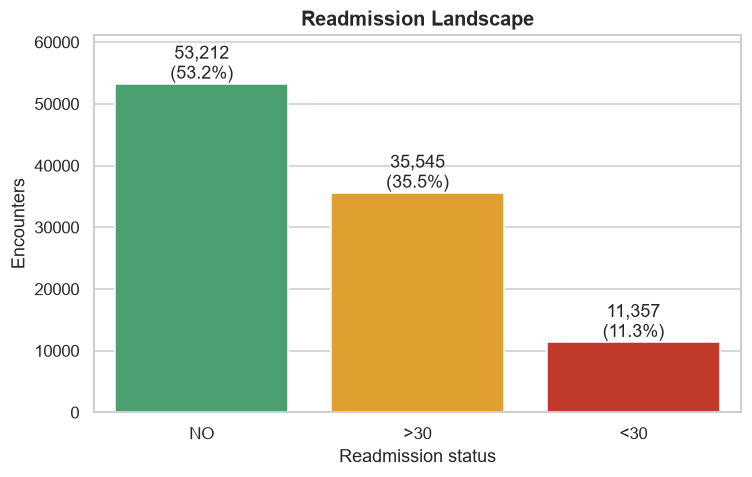

Class imbalance: NO is 4.7x larger than <30.
Raw counts mislead (the <30 bar looks small), so later charts use RATES per group.


In [24]:
# Cell 3: 3.1 The readmission landscape (class imbalance)
counts = df["readmitted"].value_counts().reindex(READMIT_ORDER)
shares = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df, x="readmitted", order=READMIT_ORDER, color="#2f6f9f", ax=ax)
for patch, status in zip(ax.patches, READMIT_ORDER):      # colour each bar by status
    patch.set_facecolor(READMIT_COLORS[status])
ax.bar_label(ax.containers[0], labels=[f"{c:,}\n({s:.1f}%)" for c, s in zip(counts, shares)])
ax.set(title="Readmission Landscape", xlabel="Readmission status", ylabel="Encounters")
ax.set_ylim(0, counts.max() * 1.15)
save_fig("01_readmission_landscape")

print(f"Class imbalance: NO is {counts['NO'] / counts['<30']:.1f}x larger than <30.")
print("Raw counts mislead (the <30 bar looks small), so later charts use RATES per group.")

**Interpretation.** 53.2% of encounters are never readmitted, 35.5% are readmitted after 30 days and only **11.3% (11,357 encounters)** are readmitted within 30 days, so "no readmission" is about 4.7 times larger than the penalty group. Consequences: (1) raw counts hide the problem, so we use **rates** from here on; (2) a naive model that always predicts "not `<30`" would be about 88.7% accurate while catching no one, so any later model must be judged on recall, precision and AUC and not on accuracy. Note also that our computed 11.3% is lower than the fictional 18% quoted in the brief, so the report should use our measured figure.

### 3.3 Demographic profiling: age
**What:** (left) the number of encounters per 10-year age group and (right) the `<30` readmission rate per age group, plus a chi-square test.  
**Why:** the brief asks whether diabetes predominantly affects the elderly in this cohort, and whether risk changes with age. Showing volume and rate side by side separates "who is in the hospital" from "who comes back".

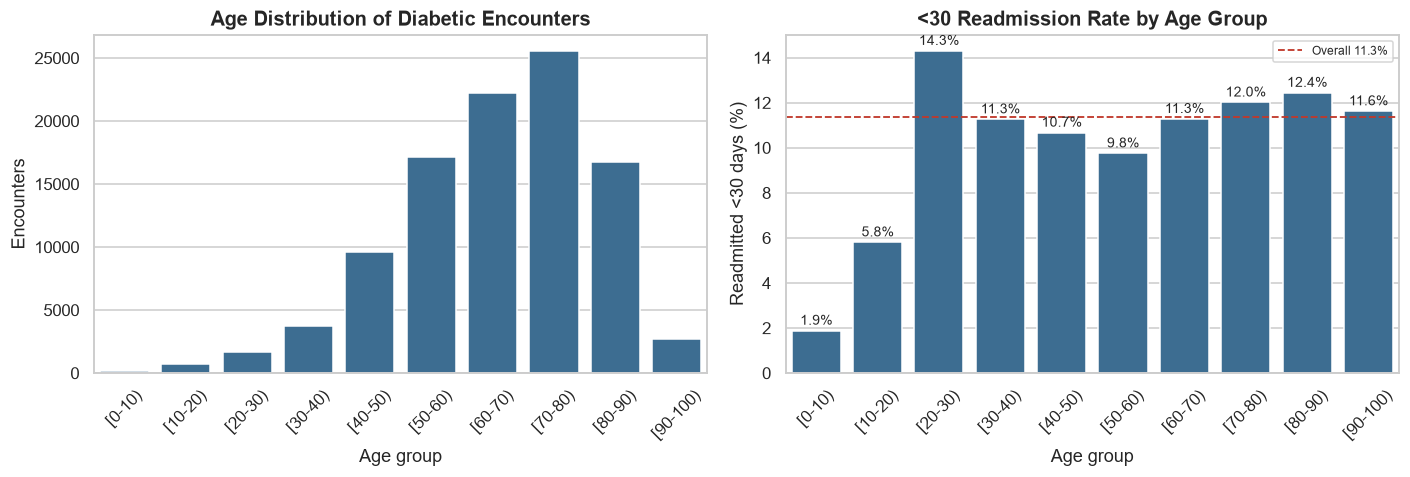

Patients aged 60+: 67.0% of encounters
Age vs <30 readmission: chi2=128.5, dof=9, p=2.41e-23 -> significant


In [25]:
# Cell 4: 3.2 Demographic profiling: age
age_order = sorted(df["age"].dropna().unique(), key=lambda a: int(a.strip("[(").split("-")[0]))
age_rates = rate_table(df, "age").reindex(age_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="age", order=age_order, color="#2f6f9f", ax=axes[0])
axes[0].set(title="Age Distribution of Diabetic Encounters", xlabel="Age group", ylabel="Encounters")
axes[0].tick_params(axis="x", rotation=45)
plot_rate_bar(axes[1], age_rates, "<30 Readmission Rate by Age Group", "Age group", rotate=45)
save_fig("02_age_distribution_and_rate")

senior_share = df["age"].isin(["[60-70)", "[70-80)", "[80-90)", "[90-100)"]).mean() * 100
print(f"Patients aged 60+: {senior_share:.1f}% of encounters")
chi2_report(df, "age", "Age vs <30 readmission")

**Interpretation.** Diabetes admissions are concentrated in older adults: **67.0%** of encounters are patients aged 60 or over. The readmission rate rises with age after the 50s, from 9.8% (age 50-59) to about 12% for ages 70-89, and the age effect is statistically significant (p < 0.001). The 20-29 group also shows a high rate (14.3%), but it is a relatively small group, so we treat that figure with caution. Older patients are therefore both the largest group and a higher-risk group, which makes them the natural focus for discharge planning.

### 3.4 Demographic profiling: race and gender
**What:** a grouped bar chart ("Readmission by Race and Gender"), a table of sample sizes, and chi-square tests for race and for gender.  
**Why:** the brief asks us to check for disparities that might signal unequal care. We show the sample sizes because rates from very small groups are unreliable, and we test significance so that apparent gaps are not over-interpreted.

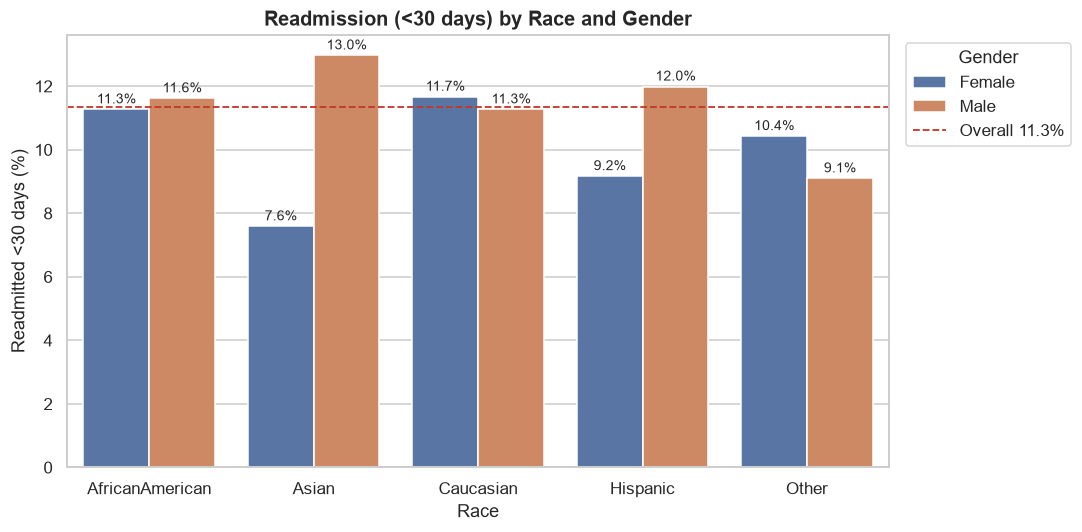

gender,Female (n),Male (n)
race,,
AfricanAmerican,11531,7357
Asian,316,316
Caucasian,39067,35778
Hispanic,1090,934
Other,738,747


Race vs <30 readmission: chi2=6.9, dof=4, p=1.40e-01 -> not significant
Gender vs <30 readmission: chi2=0.7, dof=1, p=4.09e-01 -> not significant
Largest gap between any race-gender group: 5.38 percentage points


In [26]:
# Cell 5: 3.2 Demographic profiling: race x gender
race_gender = rate_table(df, ["race", "gender"]).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=race_gender, x="race", y="rate_pct", hue="gender",
            hue_order=["Female", "Male"], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)
ax.axhline(OVERALL_RATE, color="#c0392b", ls="--", lw=1.2, label=f"Overall {OVERALL_RATE:.1f}%")
ax.set(title="Readmission (<30 days) by Race and Gender", xlabel="Race",
       ylabel="Readmitted <30 days (%)")
ax.legend(title="Gender", loc="upper left", bbox_to_anchor=(1.01, 1))
save_fig("03_readmission_by_race_gender")

display(race_gender.pivot(index="race", columns="gender", values="encounters")
        .rename(columns=lambda c: f"{c} (n)"))   # sample sizes: small groups = noisy rates
chi2_report(df, "race", "Race vs <30 readmission")
chi2_report(df, "gender", "Gender vs <30 readmission")

gap = race_gender["rate_pct"].max() - race_gender["rate_pct"].min()
print(f"Largest gap between any race-gender group: {gap:.2f} percentage points")

**Interpretation.** Neither race (p = 0.14) nor gender (p = 0.41) is statistically significant on its own, so we find **no evidence of a broad disparity**. The largest gap between any two race-gender groups is 5.4 percentage points, driven by Asian patients (female 7.6% vs male 13.0%). However, each of those two groups has only 316 patients, so the difference is likely noise and should not be reported as a disparity. We recommend monitoring these groups as more data becomes available instead of drawing conclusions now.

### 3.5 Medication efficacy: insulin vs oral vs none
**What:** classify each encounter into one of four regimens (*No diabetes medication*, *Oral only*, *Insulin only*, *Insulin + Oral*) and compare their `<30` rates.  
**Why:** the brief asks whether insulin therapy signals a sicker patient with higher risk. Insulin and oral drugs can be taken together, so four mutually exclusive groups are clearer than a simple insulin/non-insulin split. The classification is vectorised (`np.select`, `.any(axis=1)`) and not row-by-row, which is much faster on 100,000 rows.

,encounters,readmitted_lt30,rate_pct
med_group,,,
No diabetes medication,22842,2246,9.83
Oral only,23838,2510,10.53
Insulin only,30202,4000,13.24
Insulin + Oral,23232,2601,11.20


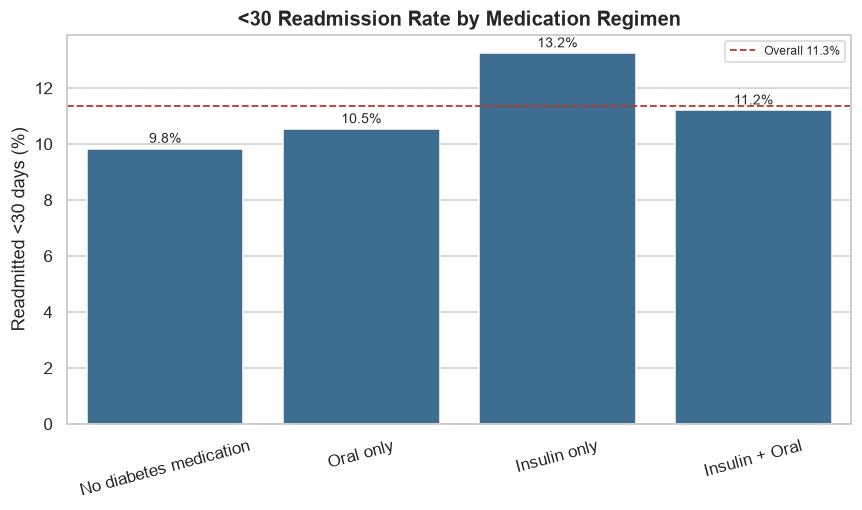

Medication regimen vs <30 readmission: chi2=176.5, dof=3, p=4.94e-38 -> significant
Any insulin: 12.35% vs no insulin: 10.19% (ratio 1.21x)


In [27]:
# Cell 6: 3.3 Medication efficacy: insulin vs oral vs none
# ORAL_MED_COLS (22 columns) was defined in Phase 1, Cell 4
on_insulin = df["insulin"].ne("No")
on_oral = df[ORAL_MED_COLS].ne("No").any(axis=1)

df["med_group"] = np.select(
    [on_insulin & on_oral, on_insulin, on_oral],
    ["Insulin + Oral", "Insulin only", "Oral only"],
    default="No diabetes medication",
)
med_order = ["No diabetes medication", "Oral only", "Insulin only", "Insulin + Oral"]
med_rates = rate_table(df, "med_group").reindex(med_order)
display(med_rates)

fig, ax = plt.subplots(figsize=(8, 4.8))
plot_rate_bar(ax, med_rates, "<30 Readmission Rate by Medication Regimen", rotate=15)
save_fig("04_medication_regimen")

chi2_report(df, "med_group", "Medication regimen vs <30 readmission")
insulin_any = df.loc[on_insulin, "readmit_30"].mean() * 100
non_insulin = df.loc[~on_insulin, "readmit_30"].mean() * 100
print(f"Any insulin: {insulin_any:.2f}% vs no insulin: {non_insulin:.2f}% "
      f"(ratio {insulin_any / non_insulin:.2f}x)")

**Interpretation.** Risk is lowest for patients on no diabetes medication (9.83%) and oral drugs only (10.53%), and highest for **insulin only (13.24%)**. Patients on both insulin and oral drugs sit in between (11.20%). Overall, patients on any insulin are readmitted at 12.35% versus 10.19% without it, about **1.21 times** as often. The difference is statistically significant, but it is much smaller than the "2x" used as an *example* in the project brief, so the report should state the measured figure. Insulin probably marks greater disease severity (it is usually the next step when oral drugs are not enough), so it works as a risk signal and not as proof that insulin causes readmission.

### 3.6 Medication changes and insulin dose adjustments
**What:** compare readmission rates for (a) whether any medication was changed during the stay and (b) the insulin status (*No*, *Steady*, *Down*, *Up*).  
**Why:** a change in therapy during the stay may indicate an unstable patient who is still being stabilised at discharge. The `insulin` column lets us look at the direction of the change, not just whether one happened.

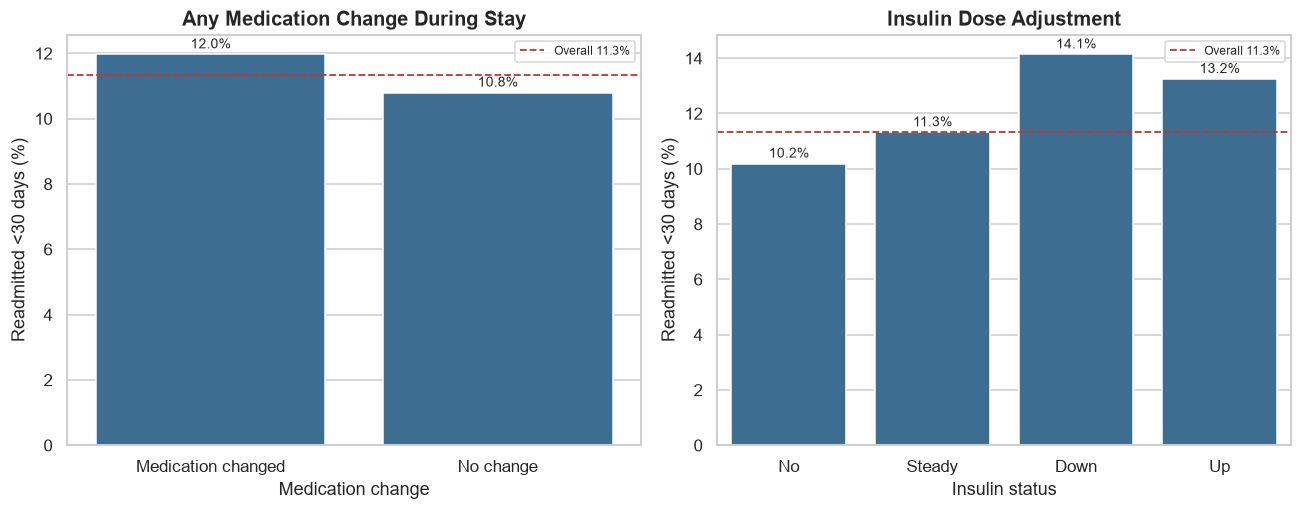

Medication change vs <30 readmission: chi2=33.3, dof=1, p=7.70e-09 -> significant
Insulin status vs <30 readmission: chi2=195.3, dof=3, p=4.34e-42 -> significant


,encounters,readmitted_lt30,rate_pct
insulin,,,
No,46680,4756,10.19
Steady,30331,3433,11.32
Down,12012,1698,14.14
Up,11091,1470,13.25


In [28]:
# Cell 7: 3.3 Medication changes and insulin dose adjustments
change_rates = rate_table(df, "change").rename(index={"Ch": "Medication changed", "No": "No change"})
insulin_order = ["No", "Steady", "Down", "Up"]
insulin_rates = rate_table(df, "insulin").reindex(insulin_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
plot_rate_bar(axes[0], change_rates, "Any Medication Change During Stay", "Medication change")
plot_rate_bar(axes[1], insulin_rates, "Insulin Dose Adjustment", "Insulin status")
save_fig("05_medication_change")

chi2_report(df, "change", "Medication change vs <30 readmission")
chi2_report(df, "insulin", "Insulin status vs <30 readmission")
display(insulin_rates)

**Interpretation.** Patients whose medication changed during the stay are readmitted slightly more often (**11.97%** vs 10.80% with no change). For insulin, both dose changes carry more risk than staying steady: dose reduced 14.14% and dose increased 13.25%, compared with 11.32% for a steady dose and 10.19% for no insulin. Both differences are statistically significant. The pattern supports the idea that a **change in insulin dose is a marker of instability** and a useful trigger for extra follow-up.

### 3.7 Operational metrics: stay length vs lab procedures
**What:** a scatter plot with a regression line (on a 5,000-row random sample so the plot stays readable), a box plot of lab procedures per day of stay, and Pearson and Spearman correlations.  
**Why:** the brief asks whether the relationship is linear. We use both coefficients because Spearman also captures non-linear but consistently increasing relationships. Jitter spreads out the whole-number day values so the dots do not stack.

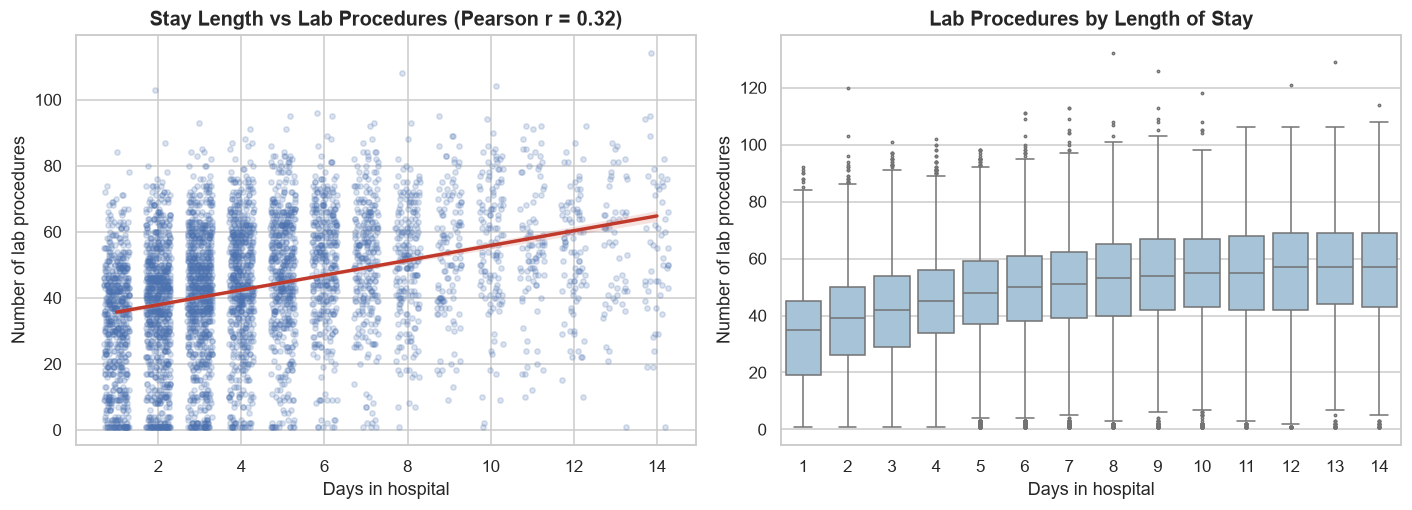

Pearson r = 0.320 (p=0.0e+00) | Spearman rho = 0.339


In [29]:
# Cell 8: 3.4 Operational: stay length vs lab procedures
r_pearson, p_pearson = stats.pearsonr(df["time_in_hospital"], df["num_lab_procedures"])
r_spearman, _ = stats.spearmanr(df["time_in_hospital"], df["num_lab_procedures"])

sample = df.sample(5000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.regplot(data=sample, x="time_in_hospital", y="num_lab_procedures",
            x_jitter=0.3, scatter_kws={"alpha": 0.2, "s": 12}, line_kws={"color": "#c0392b"},
            ax=axes[0])
axes[0].set(title=f"Stay Length vs Lab Procedures (Pearson r = {r_pearson:.2f})",
            xlabel="Days in hospital", ylabel="Number of lab procedures")
sns.boxplot(data=df, x="time_in_hospital", y="num_lab_procedures", color="#9ec5e0",
            fliersize=1.5, ax=axes[1])
axes[1].set(title="Lab Procedures by Length of Stay", xlabel="Days in hospital",
            ylabel="Number of lab procedures")
save_fig("06_stay_vs_labs")

print(f"Pearson r = {r_pearson:.3f} (p={p_pearson:.1e}) | Spearman rho = {r_spearman:.3f}")

**Interpretation.** Longer stays go together with more lab tests, but only moderately (Pearson r = 0.32, Spearman 0.34). The relationship is positive and consistent (the rank-based Spearman coefficient agrees with Pearson), yet it is far from perfect, so stay length and testing intensity are related but not interchangeable measures of clinical effort.

### 3.8 Operational metrics: correlation heatmap
**What:** a lower-triangle heatmap of the correlations between eight numeric features, and the three strongest pairs.  
**Why:** strongly correlated features carry overlapping information (multicollinearity), which can make later models unstable. Showing only the lower triangle avoids repeating every value twice.

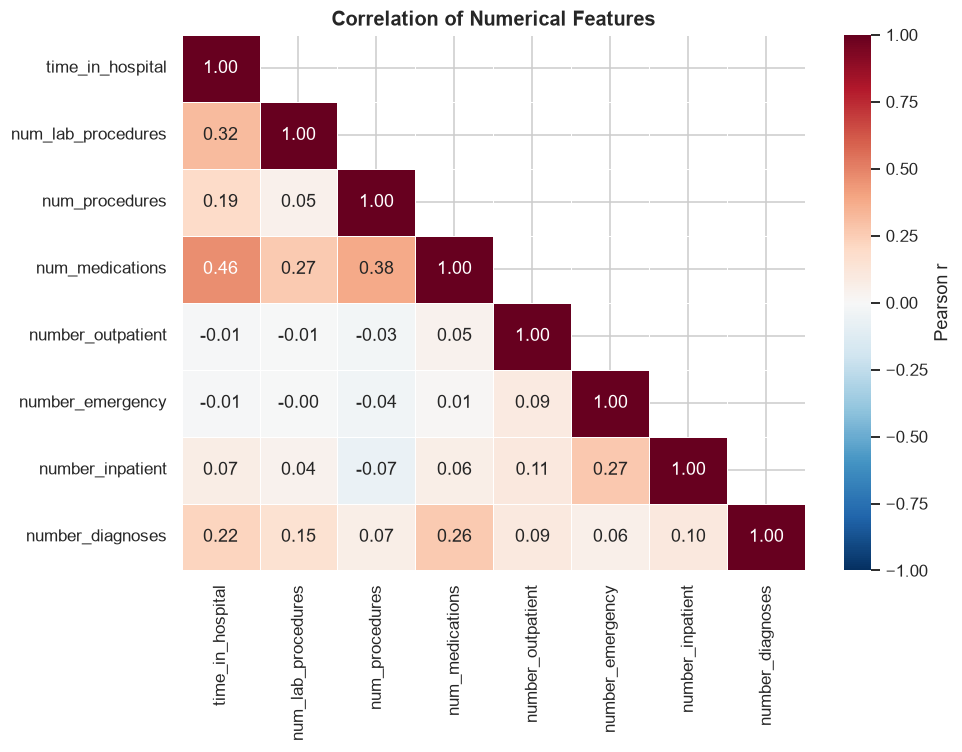

Strongest feature pairs (multicollinearity check):
num_medications     time_in_hospital    0.46
                    num_procedures      0.38
num_lab_procedures  time_in_hospital    0.32
dtype: float64


In [30]:
# Cell 9: 3.4 Operational: correlation heatmap (multicollinearity)
NUM_COLS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
corr = df[NUM_COLS].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation of Numerical Features")
save_fig("07_correlation_heatmap")

pairs = corr.where(~mask & (corr < 1)).stack().sort_values(ascending=False)
print("Strongest feature pairs (multicollinearity check):")
print(pairs.head(3).round(2))

**Interpretation.** The strongest pair is `num_medications` with `time_in_hospital` (r = 0.46), followed by `num_medications` with `num_procedures` (0.38) and `num_lab_procedures` with `time_in_hospital` (0.32). All of these are moderate, and none approaches the level (roughly 0.8 or higher) that would raise a serious multicollinearity concern. The numeric features can therefore be used together.

### 3.9 Operational metrics: stay length by readmission status
**What:** box plots of `time_in_hospital` for patients never readmitted (NO) and those readmitted within 30 days, plus the mean, median, outlier count (values above Q3 + 1.5 x IQR) and a Mann-Whitney U test.  
**Why:** the brief asks whether readmitted patients had longer initial stays and more outliers. Stay length is skewed, so we use a rank-based test (Mann-Whitney) that does not assume a normal distribution, and we report medians along with means.

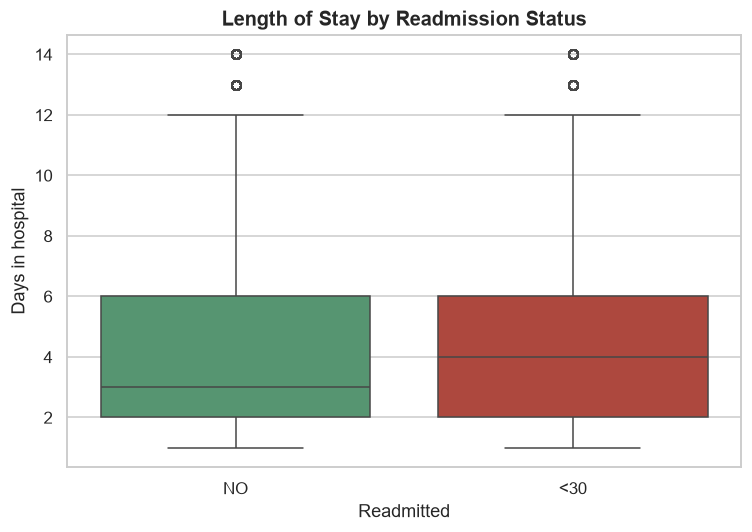

<30: mean 4.77 d, median 4 d, outliers 284 (2.5%)
 NO: mean 4.24 d, median 3 d, outliers 1,103 (2.1%)
Mann-Whitney U test (stay length, <30 vs NO): p = 5.26e-86


In [31]:
# Cell 10: 3.4 Operational: stay length by readmission status
cmp = df[df["readmitted"].isin(["NO", "<30"])].copy()
cmp["readmitted"] = cmp["readmitted"].astype(str)

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=cmp, x="readmitted", y="time_in_hospital", order=["NO", "<30"],
            hue="readmitted", palette=READMIT_COLORS, legend=False, ax=ax)
ax.set(title="Length of Stay by Readmission Status", xlabel="Readmitted",
       ylabel="Days in hospital")
save_fig("08_stay_by_readmission")


def count_outliers(series):
    """Number and share of values above the upper whisker (Q3 + 1.5 * IQR)."""
    q1, q3 = series.quantile([0.25, 0.75])
    n = (series > q3 + 1.5 * (q3 - q1)).sum()
    return n, n / len(series) * 100


for group, sub in cmp.groupby("readmitted"):
    n_out, pct_out = count_outliers(sub["time_in_hospital"])
    print(f"{group:>3}: mean {sub['time_in_hospital'].mean():.2f} d, "
          f"median {sub['time_in_hospital'].median():.0f} d, outliers {n_out:,} ({pct_out:.1f}%)")

u, p = stats.mannwhitneyu(cmp.loc[cmp["readmitted"] == "<30", "time_in_hospital"],
                          cmp.loc[cmp["readmitted"] == "NO", "time_in_hospital"])
print(f"Mann-Whitney U test (stay length, <30 vs NO): p = {p:.2e}")

**Interpretation.** Patients readmitted within 30 days had longer initial stays: a mean of 4.77 days against 4.24 and a median of 4 days against 3. The difference is statistically significant (Mann-Whitney p < 0.001) but modest in practical terms. Outliers are not a notable feature: 2.5% of the `<30` group are unusually long stays against 2.1% for the NO group.

### 3.10 Operational metrics: discharge destination (SNF vs Home)
**What:** the `<30` rate for each main discharge destination, with unusable labels (`NULL`, `Not Mapped`, `Unknown/Invalid`) excluded, and a chi-square test of Skilled Nursing Facility (SNF) versus Home.  
**Why:** the brief asks whether patients sent to a skilled nursing facility return more often than those sent home. Long descriptions are shortened for readable chart labels, and groups are sorted by rate so the riskiest destinations stand out.

,encounters,readmitted_lt30,rate_pct
discharge_group,,,
Rehab facility,1993,552,27.70
Other inpatient care,1184,247,20.86
Short-term hospital,2128,342,16.07
Skilled Nursing Facility (SNF),13954,2046,14.66
Home with home health,12902,1638,12.70
Home,60234,5602,9.30


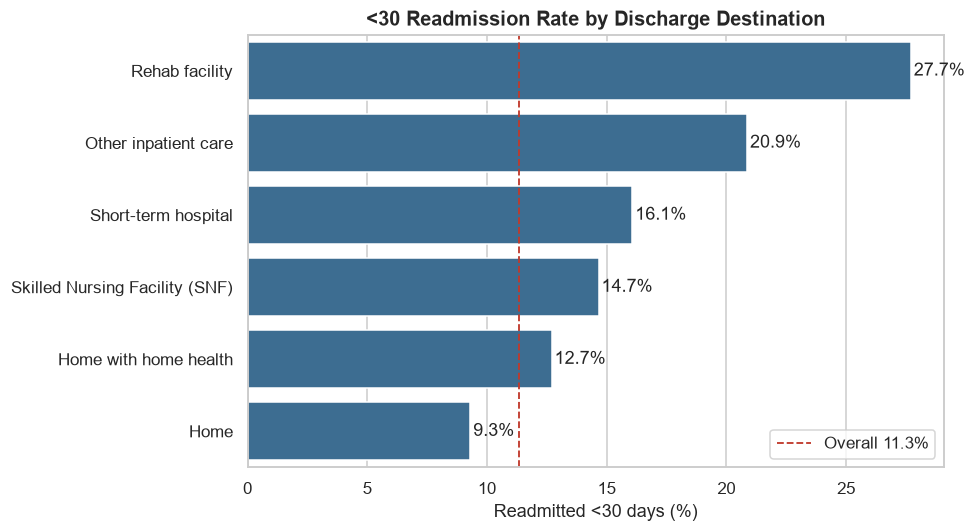

SNF vs Home: chi2=351.7, dof=1, p=1.79e-78 -> significant


In [32]:
# Cell 11: 3.4 Operational: discharge disposition (SNF vs Home)
# Drop unusable labels (the mapping file contains 'NULL', 'Not Mapped', 'Unknown/Invalid')
SHORT = {
    "Discharged to home": "Home",
    "Discharged/transferred to a Skilled Nursing Facility (SNF)": "Skilled Nursing Facility (SNF)",
    "Discharged/transferred to home with home health service": "Home with home health",
    "Discharged/transferred to another short term hospital": "Short-term hospital",
    "Discharged/transferred to another rehab fac including rehab units of a hospital .": "Rehab facility",
    "Discharged/transferred to another type of inpatient care institution": "Other inpatient care",
}
df["discharge_group"] = df["discharge_disposition_id_desc"].map(SHORT)
disc_rates = rate_table(df.dropna(subset=["discharge_group"]), "discharge_group")
disc_rates = disc_rates.sort_values("rate_pct", ascending=False)
display(disc_rates)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(y=disc_rates.index, x=disc_rates["rate_pct"], color="#2f6f9f", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
ax.axvline(OVERALL_RATE, color="#c0392b", ls="--", lw=1.2, label=f"Overall {OVERALL_RATE:.1f}%")
ax.set(title="<30 Readmission Rate by Discharge Destination", xlabel="Readmitted <30 days (%)",
       ylabel="")
ax.legend()
save_fig("09_discharge_disposition")

snf_vs_home = df[df["discharge_group"].isin(["Home", "Skilled Nursing Facility (SNF)"])]
chi2_report(snf_vs_home, "discharge_group", "SNF vs Home")

**Interpretation.** Where the patient goes after discharge matters. Patients discharged to a **Skilled Nursing Facility return at 14.66%, compared with 9.30% for those sent home**, a statistically significant difference (chi-square p < 0.001). Rehab facilities (27.70%) and other inpatient care (20.86%) are higher still, and home with home health sits in the middle (12.70%). These destinations often receive sicker patients, so this is a risk marker and not purely a quality-of-care finding, but it shows where transition-of-care handoffs deserve the most attention.

### 3.11 Prior utilisation: the strongest predictors
**What:** the `<30` rate by number of inpatient visits and emergency visits in the previous year (grouped as 0, 1, 2, 3+), and the correlation of every numeric feature with the target.  
**Why:** prior utilisation is described in the data dictionary as a "super-utilizer" signal. Grouping the counts into four buckets keeps the chart readable, and ranking all numeric features by their correlation with `<30` readmission shows which one is the strongest single predictor. This evidence also justifies the **E (Emergency visits)** component of the Vitality Complexity Index in Phase 4.

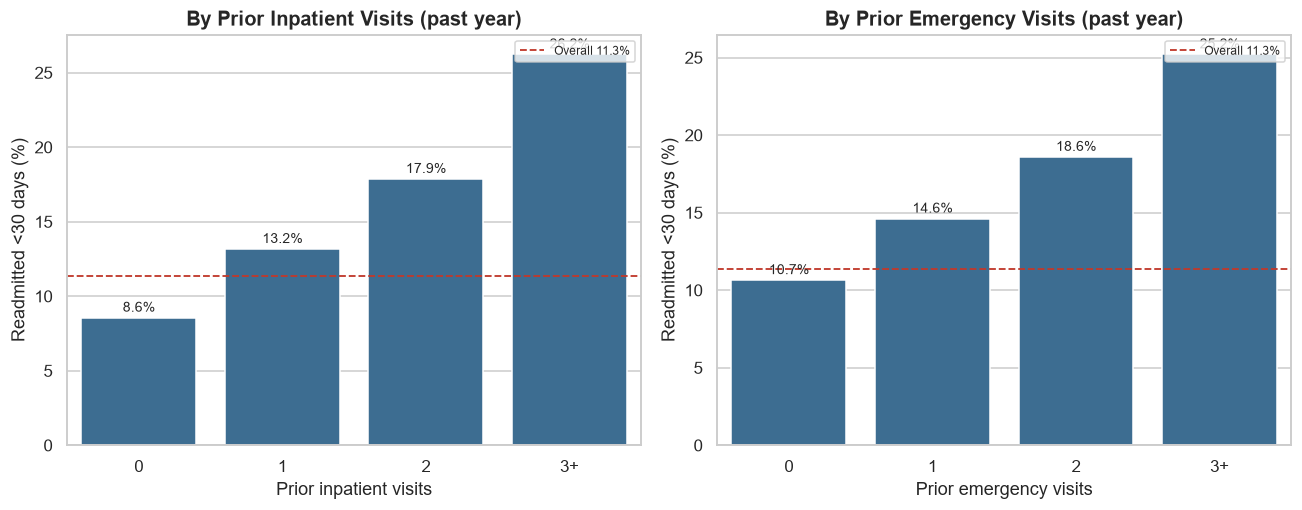

Correlation of each numeric feature with <30 readmission:
number_inpatient      0.168
number_emergency      0.061
number_diagnoses      0.052
time_in_hospital      0.046
num_medications       0.041
num_lab_procedures    0.023
number_outpatient     0.019
num_procedures       -0.010
dtype: float64


In [33]:
# Cell 12: Prior utilisation: the strongest predictors
def bucket(series):
    return pd.cut(series, bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])


df["prior_inpatient"] = bucket(df["number_inpatient"])
df["prior_emergency"] = bucket(df["number_emergency"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
plot_rate_bar(axes[0], rate_table(df, "prior_inpatient"),
              "By Prior Inpatient Visits (past year)", "Prior inpatient visits")
plot_rate_bar(axes[1], rate_table(df, "prior_emergency"),
              "By Prior Emergency Visits (past year)", "Prior emergency visits")
save_fig("10_prior_utilisation")

target_corr = (df[NUM_COLS].corrwith(df["readmit_30"]).sort_values(ascending=False).round(3))
print("Correlation of each numeric feature with <30 readmission:")
print(target_corr)

**Interpretation.** This is the clearest pattern in the data. The `<30` rate climbs steeply with the number of prior inpatient visits: **8.56% with none, 13.17% with one, 17.87% with two and 26.23% with three or more**, a threefold increase. Prior emergency visits follow the same shape (10.65% with none up to 25.21% with three or more). `number_inpatient` is also the numeric feature most correlated with readmission (r = 0.17), well ahead of `number_emergency` (0.06) and `number_diagnoses` (0.05). Patients with repeated recent admissions are the true high-risk group.

### 3.12 Phase 3 key findings table
**What:** collect the headline numbers into a single table.  
**Why:** it gives the report writer one place to look up the figures quoted in the Executive Summary and the Clinical Insights section, which avoids copy errors between the notebook and the report.

In [34]:
# Cell 13: Phase 3 key findings (feeds the report)
snf = disc_rates.loc["Skilled Nursing Facility (SNF)", "rate_pct"]
home = disc_rates.loc["Home", "rate_pct"]
key_findings = pd.Series({
    "Overall <30 readmission rate (%)": round(OVERALL_RATE, 2),
    "Patients aged 60+ (%)": round(senior_share, 1),
    "Highest-risk regimen": med_rates["rate_pct"].idxmax(),
    "  its <30 rate (%)": med_rates["rate_pct"].max(),
    "Lowest-risk regimen": med_rates["rate_pct"].idxmin(),
    "  its <30 rate (%)  ": med_rates["rate_pct"].min(),
    "Medication changed: <30 rate (%)": change_rates.loc["Medication changed", "rate_pct"],
    "No change: <30 rate (%)": change_rates.loc["No change", "rate_pct"],
    "SNF discharge <30 rate (%)": snf,
    "Home discharge <30 rate (%)": home,
    "Strongest numeric predictor": target_corr.index[0],
})
key_findings.to_frame("value")

,value
Overall <30 readmission rate (%),11.34
Patients aged 60+ (%),67.0
Highest-risk regimen,Insulin only
its <30 rate (%),13.24
Lowest-risk regimen,No diabetes medication
its <30 rate (%),9.83
Medication changed: <30 rate (%),11.97
No change: <30 rate (%),10.8
SNF discharge <30 rate (%),14.66
Home discharge <30 rate (%),9.3


---
# Phase 4: Feature Engineering - the Vitality Complexity Index (VCI)

**Objective:** translate clinical intuition into a programmable score that nursing staff can read at a glance, and test whether it really separates high-risk from low-risk patients.

**Why this matters:** discharge planners cannot study 100,000 records. A single number per patient, built from information that is already in the chart, lets them focus follow-up effort where it is most likely to prevent a penalised readmission. The VCI is a simplified variant of the validated **LACE index**.

**The score:** `VCI_Score = L + A + C + E`

| Component | Based on | Points |
|---|---|---|
| **L**: Length of stay | `time_in_hospital` | under 1 day = 0, 1-4 = 1, 5-13 = 4, 14 or more = 7 |
| **A**: Acuity of admission | `admission_type_id` | Emergency (1) or Trauma Center (7) = 3, otherwise 0 |
| **C**: Comorbidity burden (proxy) | `number_diagnoses` | under 4 = 0, 4-7 = 3, 8 or more = 5 |
| **E**: Emergency visits | `number_emergency` | 0 = 0, 1-4 = 3, more than 4 = 5 |

**Risk tiers:** Low (VCI under 7), Medium (7 to 10), High (over 10).

**Validation idea:** if the score is useful, the 30-day readmission rate should rise from the Low tier to the High tier. We test this with the required chart and with extra measures (a smooth-gradient check, component analysis, AUC and a staffing view).

### 4.0 Configuration and mapping check
**What:** define the tier names and colours, list the admission IDs that count as "acute" (1 and 7), and display those IDs from the mapping file.  
**Why:** the project brief and the data dictionary describe ID 7 differently (Emergency Room as an admission *source*, Trauma Center as an admission *type*). The scoring rule uses `admission_type_id`, so we confirm from `IDs_mapping.csv` that ID 1 is Emergency and ID 7 is Trauma Center before using them. Keeping the IDs in one constant makes the rule easy to audit and change.

In [35]:
# Needs Phase 1 (df, id_maps) and Phase 3 Cells 3.0-3.1 (helpers, readmit_30, OVERALL_RATE)
TIER_ORDER = ["Low", "Medium", "High"]
TIER_COLORS = {"Low": "#4c9f70", "Medium": "#e0a030", "High": "#c0392b"}

# Acuity rule: "Emergency" (ID 1) or "Trauma Center" (ID 7) in admission_type_id
EMERGENCY_ADMISSION_IDS = [1, 7]

# Confirm the IDs really mean what the scoring rule assumes
admission_types = id_maps["admission_type_id"]
display(admission_types[admission_types["admission_type_id"].isin(EMERGENCY_ADMISSION_IDS)])

,admission_type_id,description
0,1,Emergency
6,7,Trauma Center


### 4.1 Scoring functions for L, A, C and E
**What:** one small function per component, plus `assign_risk_tier()`, each returning the points defined by the scoring rules.  
**Why:** the brief requires the VCI to be built with functions and conditional logic, and one function per rule keeps each piece readable, testable and reusable. We apply them with `.apply()` instead of looping through rows with `iterrows()`, which is much slower on 100,000 rows. Thresholds use `<=` on whole numbers (for example `days <= 4`), which is equivalent to the "1-4 days" wording and avoids gaps between ranges.

In [36]:
def calculate_L_points(days):
    """L - Length of stay: <1 day = 0, 1-4 = 1, 5-13 = 4, 14+ = 7."""
    if days < 1:
        return 0
    elif days <= 4:
        return 1
    elif days <= 13:
        return 4
    return 7


def calculate_A_points(admission_type_id):
    """A - Acuity: Emergency (1) or Trauma Center (7) = 3 points, otherwise 0."""
    return 3 if admission_type_id in EMERGENCY_ADMISSION_IDS else 0


def calculate_C_points(number_diagnoses):
    """C - Comorbidity burden (proxy): <4 = 0, 4-7 = 3, 8+ = 5."""
    if number_diagnoses < 4:
        return 0
    elif number_diagnoses <= 7:
        return 3
    return 5


def calculate_E_points(number_emergency):
    """E - Emergency visits in the prior year: 0 = 0, 1-4 = 3, more than 4 = 5."""
    if number_emergency == 0:
        return 0
    elif number_emergency <= 4:
        return 3
    return 5


def assign_risk_tier(score):
    """Stratify the VCI: Low < 7, Medium 7-10, High > 10."""
    if score < 7:
        return "Low"
    elif score <= 10:
        return "Medium"
    return "High"

### 4.2 Unit tests on the rule boundaries
**What:** assert the expected points for values on both sides of every threshold (for example 4 and 5 days, 7 and 8 diagnoses).  
**Why:** boundary mistakes (such as `<` instead of `<=`) are the most common bugs in score logic and would silently change which patients are labelled high-risk. If any assertion fails, the notebook stops here, so errors cannot spread into the results.

In [37]:
# Boundary tests: every threshold in the specification is checked on both sides.
assert [calculate_L_points(d) for d in (0, 1, 4, 5, 13, 14)] == [0, 1, 1, 4, 4, 7]
assert [calculate_A_points(i) for i in (1, 7, 2, 3, 5)] == [3, 3, 0, 0, 0]
assert [calculate_C_points(n) for n in (1, 3, 4, 7, 8, 16)] == [0, 0, 3, 3, 5, 5]
assert [calculate_E_points(n) for n in (0, 1, 4, 5, 20)] == [0, 3, 3, 5, 5]
assert [assign_risk_tier(s) for s in (0, 6, 7, 10, 11, 20)] == \
       ["Low", "Low", "Medium", "Medium", "High", "High"]
print("All boundary tests passed.")

All boundary tests passed.


### 4.3 Compute the VCI for every patient
**What:** create four component columns (`L_points`, `A_points`, `C_points`, `E_points`), add them into `VCI_Score`, and assign each patient an ordered risk tier in `VCI_Tier`.  
**Why:** keeping the component columns, and not only the total, lets us see which parts of the score do the work (Step 4.8). The tier is stored as an *ordered* category (Low < Medium < High) so that charts and tables keep the natural order.

In [38]:
df["L_points"] = df["time_in_hospital"].apply(calculate_L_points)
df["A_points"] = df["admission_type_id"].astype(int).apply(calculate_A_points)
df["C_points"] = df["number_diagnoses"].apply(calculate_C_points)
df["E_points"] = df["number_emergency"].apply(calculate_E_points)

df["VCI_Score"] = df["L_points"] + df["A_points"] + df["C_points"] + df["E_points"]
df["VCI_Tier"] = pd.Categorical(df["VCI_Score"].apply(assign_risk_tier),
                                categories=TIER_ORDER, ordered=True)

print(f"VCI range: {df['VCI_Score'].min()} to {df['VCI_Score'].max()} (theoretical maximum 20)")
df[["time_in_hospital", "admission_type_id", "number_diagnoses", "number_emergency",
    "L_points", "A_points", "C_points", "E_points", "VCI_Score", "VCI_Tier"]].head(8)

VCI range: 1 to 20 (theoretical maximum 20)


,time_in_hospital,admission_type_id,number_diagnoses,number_emergency,L_points,A_points,C_points,E_points,VCI_Score,VCI_Tier
0,1,6,1,0,1,0,0,0,1,Low
1,3,1,9,0,1,3,5,0,9,Medium
2,2,1,6,0,1,3,3,0,7,Medium
3,2,1,7,0,1,3,3,0,7,Medium
4,1,1,5,0,1,3,3,0,7,Medium
5,3,2,9,0,1,0,5,0,6,Low
6,4,3,7,0,1,0,3,0,4,Low
7,5,1,8,0,4,3,5,0,12,High


### 4.4 Cross-check with an independent implementation
**What:** recompute the score a second way using vectorised `np.select` and assert that it matches the function-based score for every row.  
**Why:** two independent implementations that agree on all 100,114 encounters are strong evidence that the logic is translated correctly. The printout also notes that the rule "under 1 day = 0 points" never applies, because the shortest stay in the data is 1 day. We still keep the rule in the code because the specification lists it.

In [39]:
# A second implementation (np.select) must agree with the function-based one.
L = np.select([df["time_in_hospital"] < 1, df["time_in_hospital"] <= 4,
               df["time_in_hospital"] <= 13], [0, 1, 4], default=7)
A = np.where(df["admission_type_id"].astype(int).isin(EMERGENCY_ADMISSION_IDS), 3, 0)
C = np.select([df["number_diagnoses"] < 4, df["number_diagnoses"] <= 7], [0, 3], default=5)
E = np.select([df["number_emergency"] == 0, df["number_emergency"] <= 4], [0, 3], default=5)

assert (L + A + C + E == df["VCI_Score"]).all(), "VCI mismatch!"
print("Function-based VCI matches the independent calculation for all", f"{len(df):,}", "encounters.")
print("Note: the 'L < 1 day = 0 points' rule never fires because the minimum stay is",
      df["time_in_hospital"].min(), "day.")

Function-based VCI matches the independent calculation for all

 100,114 encounters.
Note: the 'L < 1 day = 0 points' rule never fires because the minimum stay is 1 day.


### 4.5 Distribution of the VCI and the risk tiers
**What:** a bar chart of the number of patients at each VCI score (coloured by tier) and a bar chart of the patients per tier.  
**Why:** before judging the score, we need to know how it behaves: its range, whether scores cluster, and how many patients would land in each tier. This also shows how large the High-risk group is, which affects the workload of any follow-up programme.

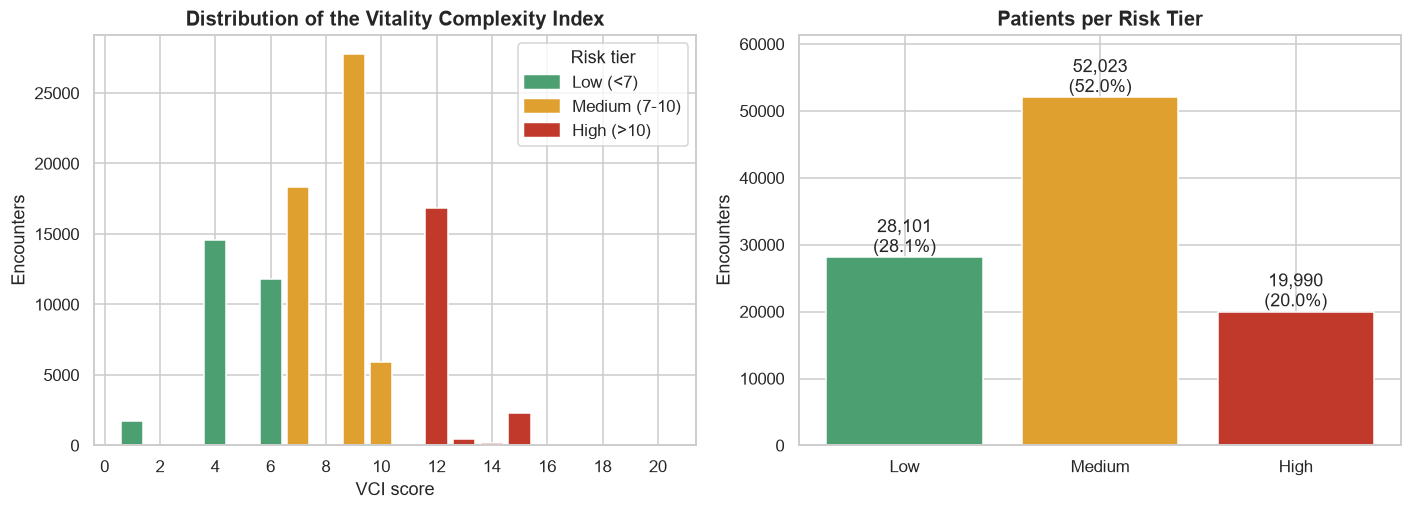

In [40]:
score_counts = df["VCI_Score"].value_counts().sort_index()
tier_of_score = {s: assign_risk_tier(s) for s in score_counts.index}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(score_counts.index, score_counts.values,
            color=[TIER_COLORS[tier_of_score[s]] for s in score_counts.index])
axes[0].set(title="Distribution of the Vitality Complexity Index", xlabel="VCI score",
            ylabel="Encounters", xticks=range(0, 21, 2))
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=TIER_COLORS[t]) for t in TIER_ORDER],
               labels=["Low (<7)", "Medium (7-10)", "High (>10)"], title="Risk tier")

tier_counts = df["VCI_Tier"].value_counts().reindex(TIER_ORDER)
axes[1].bar(TIER_ORDER, tier_counts.values, color=[TIER_COLORS[t] for t in TIER_ORDER])
axes[1].bar_label(axes[1].containers[0],
                  labels=[f"{n:,}\n({n / len(df) * 100:.1f}%)" for n in tier_counts])
axes[1].set(title="Patients per Risk Tier", ylabel="Encounters")
axes[1].set_ylim(0, tier_counts.max() * 1.18)
save_fig("11_vci_distribution")

**Interpretation.** Scores range from 1 to 20 but only 15 different values actually occur, because the score is built from a few coarse point steps. The tiers are very uneven: **Low 28.1% (28,101 patients), Medium 52.0% (52,023) and High 20.0% (19,990)**. A single score of 9 contains 27,746 patients, so the Medium tier is a large and fairly mixed group. The High tier is a manageable one-fifth of patients, which is a practical size for targeted follow-up.

### 4.6 Validation: readmission rate by risk tier
**What:** the required chart: the `<30` readmission rate for each tier, next to the full mix of readmission outcomes (NO, `>30`, `<30`) within each tier. We also compute each tier's "lift" (its rate divided by the overall rate) and run a chi-square test.  
**Why:** this is the main test of the algorithm. If the High tier does not have a clearly higher rate than the Low tier, the score is not doing its job. The stacked chart adds context by showing whether the tiers also differ in later (`>30`) readmissions.

,encounters,readmitted_lt30,rate_pct,lift_vs_overall
VCI_Tier,,,,
Low,28101,2475,8.81,0.78
Medium,52023,5938,11.41,1.01
High,19990,2944,14.73,1.30


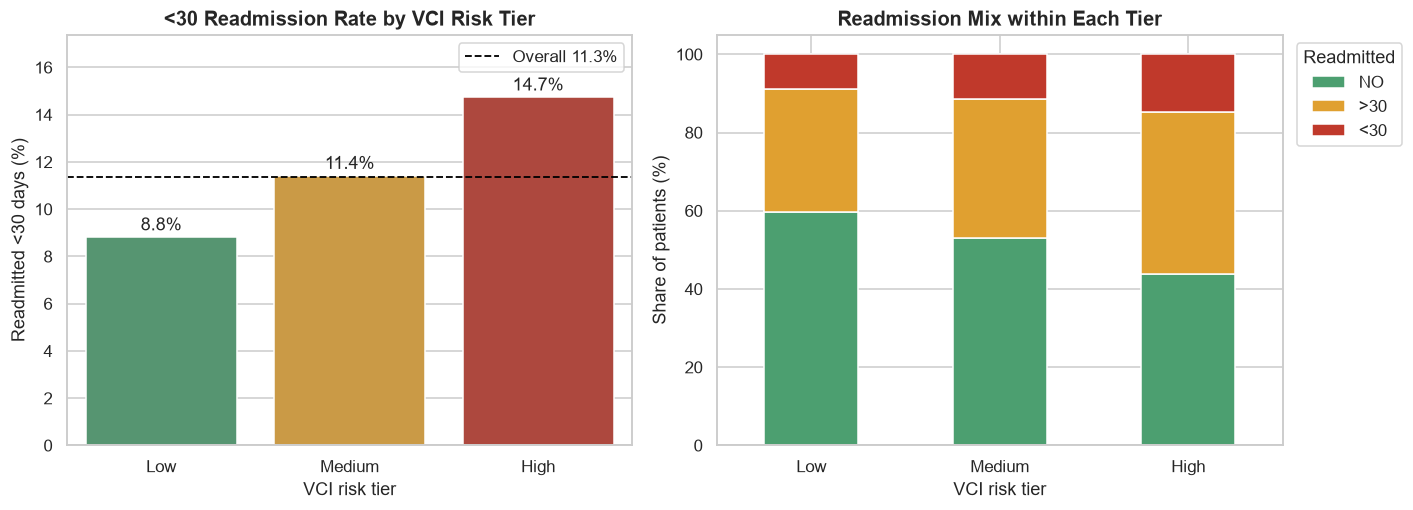

VCI tier vs <30 readmission: chi2=407.5, dof=2, p=3.18e-89 -> significant
High-risk patients are readmitted 1.67x as often as Low-risk patients.


In [41]:
tier_rates = rate_table(df, "VCI_Tier").reindex(TIER_ORDER)
tier_rates["lift_vs_overall"] = (tier_rates["rate_pct"] / OVERALL_RATE).round(2)
display(tier_rates)

status_mix = (pd.crosstab(df["VCI_Tier"], df["readmitted"], normalize="index") * 100)
status_mix = status_mix.reindex(index=TIER_ORDER, columns=READMIT_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(x=tier_rates.index.astype(str), y=tier_rates["rate_pct"],
            hue=tier_rates.index.astype(str), palette=TIER_COLORS, legend=False, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=2)
axes[0].axhline(OVERALL_RATE, color="black", ls="--", lw=1.2, label=f"Overall {OVERALL_RATE:.1f}%")
axes[0].set(title="<30 Readmission Rate by VCI Risk Tier", xlabel="VCI risk tier",
            ylabel="Readmitted <30 days (%)")
axes[0].set_ylim(0, tier_rates["rate_pct"].max() * 1.18)
axes[0].legend()

status_mix.plot(kind="bar", stacked=True, ax=axes[1],
                color=[READMIT_COLORS[s] for s in READMIT_ORDER], rot=0)
axes[1].set(title="Readmission Mix within Each Tier", xlabel="VCI risk tier",
            ylabel="Share of patients (%)")
axes[1].legend(title="Readmitted", loc="upper left", bbox_to_anchor=(1.01, 1))
save_fig("12_readmission_by_vci_tier")

chi2_report(df, "VCI_Tier", "VCI tier vs <30 readmission")
ratio = tier_rates.loc["High", "rate_pct"] / tier_rates.loc["Low", "rate_pct"]
print(f"High-risk patients are readmitted {ratio:.2f}x as often as Low-risk patients.")

**Interpretation.** The score passes the validation test: the `<30` rate rises steadily from **8.81% (Low)** to **11.41% (Medium)** to **14.73% (High)**, so High-risk patients are readmitted **1.67 times as often** as Low-risk patients (chi-square p < 0.001). Relative to the overall rate of 11.3%, the lift is 0.78 for Low, 1.01 for Medium and 1.30 for High. The stacked chart shows that the High tier also has far more readmissions after 30 days (41.4% vs 31.4% for Low), so in total 56.1% of High-risk patients return to hospital compared with 40.2% of Low-risk patients. The VCI therefore captures general readmission risk and not only the 30-day window.

### 4.7 Is the gradient smooth? Rate at every VCI score
**What:** a line chart of the `<30` rate at each individual VCI score, shading the three tiers, using only scores with at least 100 patients, plus the Spearman correlation between the score and the outcome.  
**Why:** tier averages can hide a messy pattern. Checking every score shows whether risk rises steadily with the score or jumps around. We exclude tiny groups because rates from a few patients are unreliable.

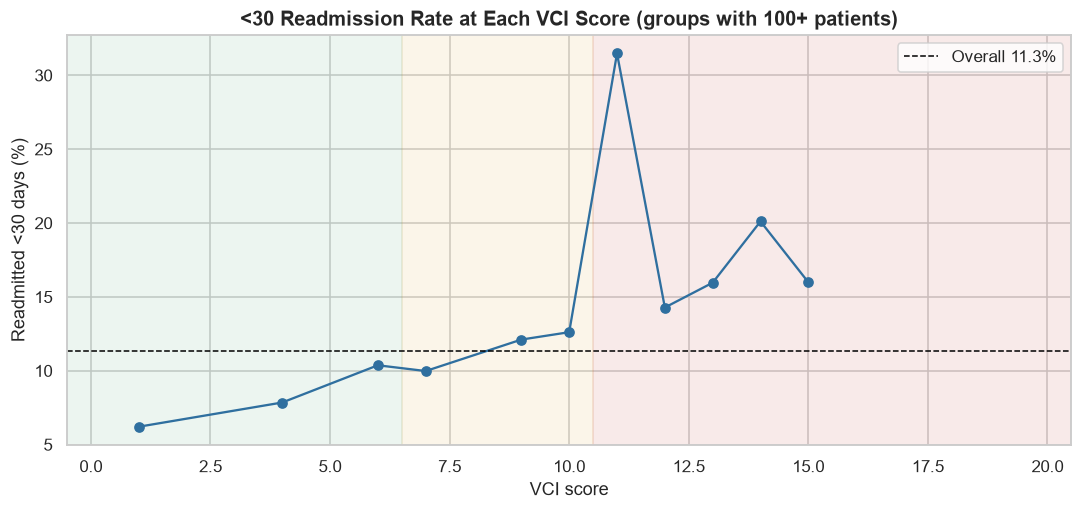

Spearman correlation between VCI and <30 readmission: 0.070 (p = 3.4e-110)


In [42]:
by_score = rate_table(df, "VCI_Score")
reliable = by_score[by_score["encounters"] >= 100]          # ignore very small groups

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(reliable.index, reliable["rate_pct"], marker="o", color="#2f6f9f")
ax.axvspan(-0.5, 6.5, color=TIER_COLORS["Low"], alpha=0.10)
ax.axvspan(6.5, 10.5, color=TIER_COLORS["Medium"], alpha=0.10)
ax.axvspan(10.5, 20.5, color=TIER_COLORS["High"], alpha=0.10)
ax.axhline(OVERALL_RATE, color="black", ls="--", lw=1, label=f"Overall {OVERALL_RATE:.1f}%")
ax.set(title="<30 Readmission Rate at Each VCI Score (groups with 100+ patients)",
       xlabel="VCI score", ylabel="Readmitted <30 days (%)", xlim=(-0.5, 20.5))
ax.legend()
save_fig("13_rate_by_vci_score")

trend, p_trend = stats.spearmanr(df["VCI_Score"], df["readmit_30"])
print(f"Spearman correlation between VCI and <30 readmission: {trend:.3f} (p = {p_trend:.1e})")

**Interpretation.** The overall direction is clearly upward: 6.2% at a score of 1, around 10% at 6 to 7, 12% to 13% at 9 to 10, and 14% to 20% for scores of 12 and above. It is not perfectly smooth: a score of 7 is slightly below 6 (9.98% vs 10.37%), and the spike at 11 (31.5%) comes from only 108 patients, so it should not be over-interpreted. The Spearman correlation is small (0.07) but highly significant, which is typical for a coarse score applied to a very large sample.

### 4.8 Which VCI component carries the signal?
**What:** the `<30` readmission rate for each point level of L, A, C and E.  
**Why:** a score is only as good as its parts. This shows whether each component's point scale makes sense (more points should mean higher risk) and which components contribute most. If a component is weak, it should be discussed honestly in the report.

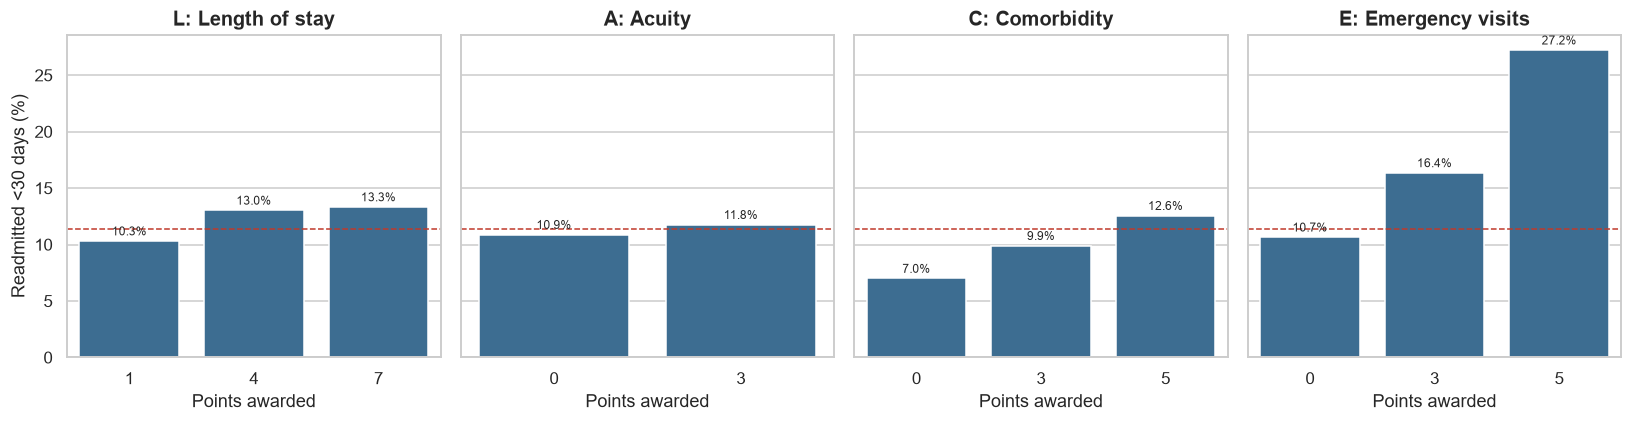

In [43]:
components = {"L_points": "L: Length of stay", "A_points": "A: Acuity",
              "C_points": "C: Comorbidity", "E_points": "E: Emergency visits"}

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
for ax, (col, name) in zip(axes, components.items()):
    tbl = rate_table(df, col)
    sns.barplot(x=tbl.index.astype(str), y=tbl["rate_pct"], color="#2f6f9f", ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2, fontsize=8)
    ax.axhline(OVERALL_RATE, color="#c0392b", ls="--", lw=1)
    ax.set(title=name, xlabel="Points awarded", ylabel="")
axes[0].set_ylabel("Readmitted <30 days (%)")
save_fig("14_vci_components")

**Interpretation.** Three components behave as intended. **Emergency visits (E)** have the steepest gradient: 10.65% with no prior visits, 16.35% with 1 to 4 and **27.22%** with more than 4 (only 562 patients, but a very high rate). **Comorbidity (C)** rises from 6.99% to 9.90% to 12.56%. **Length of stay (L)** rises from 10.31% for short stays to 13.03% for 5 to 13 days and 13.33% for 14 days or more. **Acuity (A)** is the weak link: patients admitted through emergency or trauma are readmitted at 11.76%, barely above the 10.88% of other admissions. This matters for the report, because it means "all emergency admissions" is not a strong enough reason by itself to trigger an intervention.

### 4.9 Discrimination power (AUC)
**What:** the AUC of the total VCI and of each component, computed from the Mann-Whitney U statistic (AUC is U divided by the number of patient pairs).  
**Why:** AUC answers a practical question: if we pick one patient who was readmitted within 30 days and one who was not, how often does the readmitted patient have the higher score? A value of 0.5 is pure chance and 1.0 is perfect. It gives an honest, single-number measure of strength that does not depend on where the tier cut-offs are placed.

In [44]:
def auc_score(scores, target):
    """AUC = probability that a random <30 patient scores higher than a random other patient.

    0.5 = no better than chance, 1.0 = perfect. Computed from the Mann-Whitney U statistic.
    """
    positives, negatives = scores[target == 1], scores[target == 0]
    u_stat, _ = stats.mannwhitneyu(positives, negatives)
    return u_stat / (len(positives) * len(negatives))


auc_table = pd.Series({name: auc_score(df[col], df["readmit_30"])
                       for col, name in components.items()})
auc_table["VCI (total score)"] = auc_score(df["VCI_Score"], df["readmit_30"])
auc_table = auc_table.round(3).sort_values(ascending=False).to_frame("AUC")
display(auc_table)
print("0.5 = no better than chance. Readmission scores are usually modest discriminators (often 0.6-0.7).")

,AUC
VCI (total score),0.563
C: Comorbidity,0.538
L: Length of stay,0.532
E: Emergency visits,0.531
A: Acuity,0.511


0.5 = no better than chance. Readmission scores are usually modest discriminators (often 0.6-0.7).


**Interpretation.** The total VCI has an AUC of **0.563**, better than chance (0.5) but modest. By component: comorbidity 0.538, length of stay 0.532, emergency visits 0.531 and acuity 0.511. Readmission is hard to predict from a few simple chart items, and this result is consistent with the modest accuracy usually reported for readmission scores. The VCI should therefore be presented as a **screening aid for prioritising attention**, not as a precise prediction of individual outcomes.

### 4.10 Operational utility: who gets flagged and how many readmissions do we catch?
**What:** for three possible alert cut-offs (VCI of 7 or more, 9 or more, and 11 or more, the High tier), the share of patients flagged, the `<30` rate among them and the share of all `<30` readmissions captured. A second chart compares each tier's share of patients with its share of readmissions.  
**Why:** nurse staffing is limited, so the cut-off is a trade-off between workload (how many patients are flagged) and coverage (how many future readmissions are caught). Showing both lets management choose a threshold on purpose.

,flag patients with VCI >=,patients flagged (%),<30 rate among flagged (%),share of all <30 readmissions caught (%)
0,7,71.9,12.33,78.2
1,9,53.6,13.14,62.1
2,11,20.0,14.73,25.9


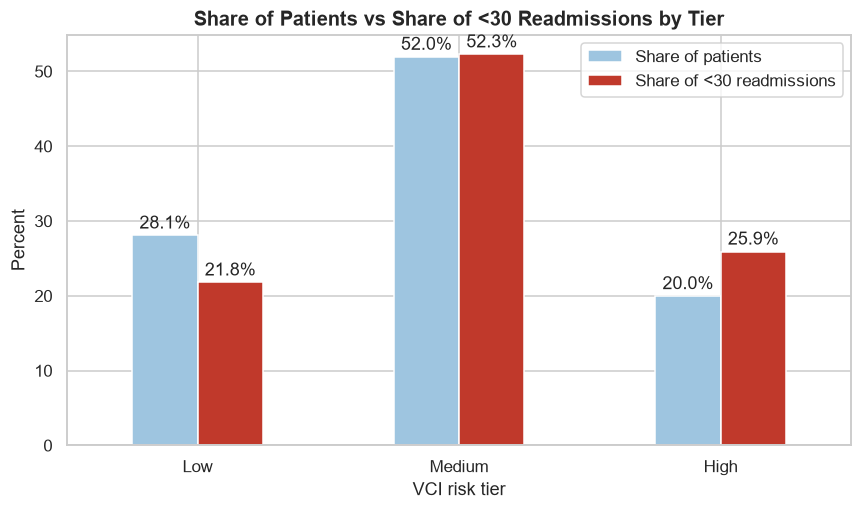

In [45]:
total_readmits = df["readmit_30"].sum()
rows = []
for cutoff in (7, 9, 11):                     # 11 = the "High" tier (VCI > 10)
    flagged = df["VCI_Score"] >= cutoff
    rows.append({
        "flag patients with VCI >=": cutoff,
        "patients flagged (%)": round(flagged.mean() * 100, 1),
        "<30 rate among flagged (%)": round(df.loc[flagged, "readmit_30"].mean() * 100, 2),
        "share of all <30 readmissions caught (%)":
            round(df.loc[flagged, "readmit_30"].sum() / total_readmits * 100, 1),
    })
cutoff_table = pd.DataFrame(rows)
display(cutoff_table)

tier_share = pd.DataFrame({
    "Share of patients": df["VCI_Tier"].value_counts(normalize=True).reindex(TIER_ORDER) * 100,
    "Share of <30 readmissions": df.groupby("VCI_Tier", observed=True)["readmit_30"].sum()
                                   .reindex(TIER_ORDER) / total_readmits * 100,
})
ax = tier_share.plot(kind="bar", figsize=(8, 4.8), color=["#9ec5e0", "#c0392b"], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2)
ax.set(title="Share of Patients vs Share of <30 Readmissions by Tier", xlabel="VCI risk tier",
       ylabel="Percent")
save_fig("15_tier_patient_vs_readmission_share")

**Interpretation.** A lower cut-off catches more readmissions but flags far more patients: a cut-off of 7 flags 71.9% of patients to catch 78.2% of readmissions, while the High tier (11 or more) flags only 20.0% of patients and catches 25.9%. The High tier holds a larger share of readmissions (25.9%) than its share of patients (20.0%), whereas the Low tier is the reverse (21.8% of readmissions from 28.1% of patients). A tiered response would work best: intensive follow-up for High, standard follow-up for Medium, and routine discharge for Low.

### 4.11 Phase 4 key findings table
**What:** collect the headline VCI results into one table.  
**Why:** one place for the figures quoted in the VCI section of the report and in the Executive Summary, which avoids transcription errors.

In [46]:
high, low = tier_rates.loc["High"], tier_rates.loc["Low"]
vci_findings = pd.Series({
    "Patients scored": f"{len(df):,}",
    "Low / Medium / High patients (%)": " / ".join(
        f"{v:.1f}" for v in (df["VCI_Tier"].value_counts(normalize=True)
                             .reindex(TIER_ORDER) * 100)),
    "<30 rate: Low (%)": low["rate_pct"],
    "<30 rate: Medium (%)": tier_rates.loc["Medium", "rate_pct"],
    "<30 rate: High (%)": high["rate_pct"],
    "High vs Low (x)": round(high["rate_pct"] / low["rate_pct"], 2),
    "VCI AUC": auc_table.loc["VCI (total score)", "AUC"],
    "Strongest single component": auc_table.drop("VCI (total score)").index[0],
    "High tier: share of patients (%)": round(tier_share.loc["High", "Share of patients"], 1),
    "High tier: share of <30 readmissions (%)":
        round(tier_share.loc["High", "Share of <30 readmissions"], 1),
})
vci_findings.to_frame("value")

,value
Patients scored,"100,114"
Low / Medium / High patients (%),28.1 / 52.0 / 20.0
<30 rate: Low (%),8.81
<30 rate: Medium (%),11.41
<30 rate: High (%),14.73
High vs Low (x),1.67
VCI AUC,0.563
Strongest single component,C: Comorbidity
High tier: share of patients (%),20.0
High tier: share of <30 readmissions (%),25.9


---
## Project summary
- **Data (Phase 1):** 100,114 clean encounters after removing 1,652 deceased patients, dropping `weight` (96.86% missing) and standardising `?` values and data types.
- **Enrichment (Phase 2):** the top 20 primary diagnoses carry readable descriptions in `Primary_Diagnosis_Desc`.
- **Drivers of readmission (Phase 3):** only 11.3% of encounters are readmitted within 30 days (a 4.7:1 imbalance). Risk is highest for patients with several prior inpatient or emergency visits, patients discharged to rehab or skilled nursing facilities, insulin users (especially with a dose change) and older patients. Race and gender show no statistically significant overall disparity.
- **Vitality Complexity Index (Phase 4):** the VCI separates risk in the right direction, with `<30` readmission rates of 8.81% (Low), 11.41% (Medium) and 14.73% (High), a 1.67x difference. The discrimination is modest (AUC 0.563), prior emergency visits and comorbidity carry most of the signal, and acuity of admission adds little.
- **Limitations to state in the report:** `weight` was unusable; two glucose-test columns are mostly "not performed"; repeated patients mean encounters are not fully independent; and the VCI is a simple screening score, not a precise predictor.
- **Possible refinement:** prior inpatient visits (the strongest predictor in Phase 3, from 8.56% with none to 26.23% with three or more) are not in the VCI and would be the first variable to add.
- **Next:** write the Strategic Insight Report (2,500-3,000 words) using the figures saved in the `figures/` folder.